# 07. GBT Tuning et Modele Final

Selection de variables, tuning du GBT et construction du jeu d entrainement optimise pour le modele final.

**Sortie principale :** `models/07_gbt_tuning_final_model/gbt_final_model`


In [1]:
# Importation des bibliothèques principales
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.functions import col, round as spark_round

from pyspark.ml.stat import *
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import  VectorAssembler , RobustScaler
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import RandomForestClassifier,LogisticRegression,GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator ,MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#  Visualisation et analyse complémentaire

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from builtins import round

import numpy as np
from sklearn.metrics import precision_recall_curve
from pyspark import StorageLevel

import json
from pyspark.ml.classification import GBTClassificationModel

from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import joblib


In [2]:
import os
from pathlib import Path
import sys
import mlflow

PROJECT_DIR = Path(os.environ.get("FRAUD_PROJECT_DIR", Path.cwd())).resolve()
if PROJECT_DIR.name in {"notebook", "notebooks"}:
    PROJECT_DIR = PROJECT_DIR.parent

NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
MLFLOW_DIR = PROJECT_DIR / "Mlflow"
MLFLOW_ARTIFACTS_DIR = MLFLOW_DIR / "artifacts"
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

STAGE_NAME = "07_gbt_tuning_final_model"
INPUT_STAGE_DIR = ARTIFACTS_ROOT / "06_modeling_baselines" / "data"
STAGE_ARTIFACTS_DIR = ARTIFACTS_ROOT / STAGE_NAME
STAGE_DATA_DIR = STAGE_ARTIFACTS_DIR / "data"
MODELS_STAGE_DIR = MODELS_ROOT / STAGE_NAME
METRICS_DIR = STAGE_ARTIFACTS_DIR / "metrics"
PLOTS_DIR = STAGE_ARTIFACTS_DIR / "plots"
FEATURE_SELECTION_DIR = STAGE_ARTIFACTS_DIR / "feature_selection"
METADATA_DIR = STAGE_ARTIFACTS_DIR / "metadata"

for _dir in (
    ARTIFACTS_ROOT,
    MODELS_ROOT,
    STAGE_ARTIFACTS_DIR,
    STAGE_DATA_DIR,
    MODELS_STAGE_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    FEATURE_SELECTION_DIR,
    METADATA_DIR,):
    _dir.mkdir(parents=True, exist_ok=True)

MLFLOW_SQLITE_URI = f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').resolve().as_posix()}"
mlflow.set_tracking_uri(MLFLOW_SQLITE_URI)
mlflow.set_registry_uri(MLFLOW_SQLITE_URI)

EXPERIMENT_NAME = "fraud_detection_ieee"
ARTIFACT_LOCATION = (MLFLOW_ARTIFACTS_DIR / EXPERIMENT_NAME).resolve().as_uri()

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=ARTIFACT_LOCATION
    )
else:
    experiment_id = experiment.experiment_id

experiment = mlflow.get_experiment(experiment_id)

assert experiment.artifact_location == ARTIFACT_LOCATION, (
    f"Mauvais artifact_location: {experiment.artifact_location}")

mlflow.set_experiment(EXPERIMENT_NAME)
print(experiment)

def _mlflow_context_label(context):
    return f" ({context})" if context else ""

def safe_mlflow_log_params(params, context=""):
    try:
        mlflow.log_params(params)
    except Exception as e:
        print(f"[MLflow] params skipped{_mlflow_context_label(context)}: {type(e).__name__}: {e}")

def safe_mlflow_log_metrics(metrics, context=""):
    try:
        mlflow.log_metrics(metrics)
    except Exception as e:
        print(f"[MLflow] metrics skipped{_mlflow_context_label(context)}: {type(e).__name__}: {e}")

def safe_mlflow_log_model(model, artifact_path, context=""):
    try:
        return mlflow.spark.log_model(model, artifact_path=artifact_path)
    except Exception as e:
        print(f"[MLflow] model log skipped{_mlflow_context_label(context)}: {type(e).__name__}: {e}")
        return None

def safe_mlflow_log_artifacts(local_dir, artifact_path=None, context=""):
    try:
        mlflow.log_artifacts(local_dir, artifact_path=artifact_path)
    except Exception as e:
        print(f"[MLflow] artifacts skipped{_mlflow_context_label(context)}: {type(e).__name__}: {e}")

def safe_to_pandas(spark_df, context=""):
    spark_session = spark_df.sparkSession
    arrow_prev = spark_session.conf.get("spark.sql.execution.arrow.pyspark.enabled", "false")
    cached_df = spark_df.persist(StorageLevel.DISK_ONLY)
    try:
        spark_session.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
        cached_df.count()
        rows = [row.asDict(recursive=True) for row in cached_df.toLocalIterator()]
        pdf = pd.DataFrame(rows)
        if context:
            print(f"[Spark->Pandas] {context}: shape={pdf.shape}")
        return pdf
    finally:
        try:
            cached_df.unpersist()
        except Exception:
            pass
        spark_session.conf.set("spark.sql.execution.arrow.pyspark.enabled", arrow_prev)


<Experiment: artifact_location='file:///C:/Users/El-fahad%20COMBO/Desktop/Fraud_Detection_IEEE/Mlflow/artifacts/fraud_detection_ieee', creation_time=1782163499721, experiment_id='53', last_update_time=1782163499721, lifecycle_stage='active', name='fraud_detection_ieee', tags={}, workspace='default'>


In [3]:
# Création de la session Spark
spark = SparkSession.builder \
    .appName("DetectionFraude") \
    .master("local[4]") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.default.parallelism", "4") \
    .getOrCreate() 

# Affichage de la session pour vérification
spark

In [4]:
# fonciton nettoyage de mémoire 
def cleanup(*vars_to_del):
    for var in vars_to_del:
        del var
    import gc; gc.collect()
    spark.catalog.clearCache()

In [ ]:
from fraud_pipeline import (
    build_added_feature_analysis,
    compute_three_way_blend_diagnostics,
    load_json,
    load_three_way_blend_models,
    save_json,
    save_three_way_blend_metadata,
    score_three_way_blend_models,
    search_best_three_way_blend,)

mlflow.end_run()
mlflow.start_run(run_name=STAGE_NAME)
mlflow.set_tag("stage", STAGE_NAME)
mlflow.set_tag("notebook", "07_gbt_tuning_final_model.ipynb")

train_df = spark.read.parquet((INPUT_STAGE_DIR / "train_features_enriched_train_split.parquet").as_posix())
valid_df = spark.read.parquet((INPUT_STAGE_DIR / "train_features_enriched_valid_split.parquet").as_posix())

STALE_GROUP_COLUMNS = [
    "uid_simple",
    "uid_simple_count",
    "TransactionAmt_uid_simple_mean",
    "TransactionAmt_uid_simple_std",
    "log1p_amt_over_uid_simple_mean",
    "is_uid_simple_rare",
    "card1_count",
    "TransactionAmt_card1_mean",
    "TransactionAmt_card1_std",
    "log1p_amt_over_card1_mean",]

stale_cols_found = [c for c in STALE_GROUP_COLUMNS if c in train_df.columns or c in valid_df.columns]
if stale_cols_found:
    print(f"Colonnes group-stats résiduelles détectées et retirées dans 07 : {stale_cols_found}")
    train_df = train_df.drop(*[c for c in stale_cols_found if c in train_df.columns])
    valid_df = valid_df.drop(*[c for c in stale_cols_found if c in valid_df.columns])
df_final = train_df.unionByName(valid_df)
split_metadata = load_json((ARTIFACTS_ROOT / "05_feature_engineering" / "metadata" / "split_metadata.json"))


# 8. Amélioration du modèle `GBTClassifier`

Objectif : **améliorer le F1-score et la précision**, tout en maintenant un haut niveau de rappel.

Le split `train/valid` reste celui préparé dans le notebook 05 pour éviter tout leakage pendant la sélection de variables, le tuning et l’évaluation finale.


## 8.1 — Sélection des variables et contrôle du risque de sur-apprentissage

On distingue ici :

- une **vue interprétable** sur des variables scalaires / ingénierées ;
- une **sélection des `Vxx`** faite uniquement sur `train_df` ;
- une construction finale qui réintègre le noyau baseline utile, les features `fp_` et les variables `Vxx` retenues.


In [6]:
print( f"Split anti-leakage conservé | seed={split_metadata['split_seed']} | "
    f"train={train_df.count()} | valid={valid_df.count()}")

Split anti-leakage conservé | seed=42 | train=472453 | valid=118087


In [7]:
# Vue interprétable : importance sur des variables scalaires / ingénierées (train slmnt)
scalar_candidate_features = [
    c for c, t in train_df.dtypes
    if t in ("double", "int", "bigint")
    and c not in {"isFraud", "classWeight", "TransactionDT", "features", "features_to_scale", "scaled_features"}
    and not c.endswith("_idx")
    and not c.startswith("V")]

assembler_scalar = VectorAssembler(inputCols=scalar_candidate_features, outputCol="scalar_features")
df_scalar = assembler_scalar.transform(train_df.select("isFraud", "classWeight", *scalar_candidate_features))

gbt_scalar = GBTClassifier(labelCol="isFraud", featuresCol="scalar_features", weightCol="classWeight", maxIter=30, seed=42)
model_scalar = gbt_scalar.fit(df_scalar)

scalar_importances = model_scalar.featureImportances.toArray()
scalar_features_importance = list(zip(scalar_candidate_features, scalar_importances))
scalar_features_sorted = sorted(scalar_features_importance, key=lambda x: x[1], reverse=True)

top_scalar_features = [name for name, score in scalar_features_sorted[:20]]
print("Top features scalaires / ingénierées (train only) :")
for f in top_scalar_features:
    print(" -", f)


Top features scalaires / ingénierées (train only) :
 - risk_card1_fraud_rate
 - risk_card1_count_log
 - uid_full_freq
 - D3
 - C14
 - C1
 - risk_device_r_fraud_rate
 - C1_sur_D1
 - C13
 - C5
 - D2
 - TransactionAmt
 - C6
 - day
 - C2
 - Amt_sur_D15
 - D8
 - C8
 - is_fn_m4_m0_productW
 - P_emaildomain_freq


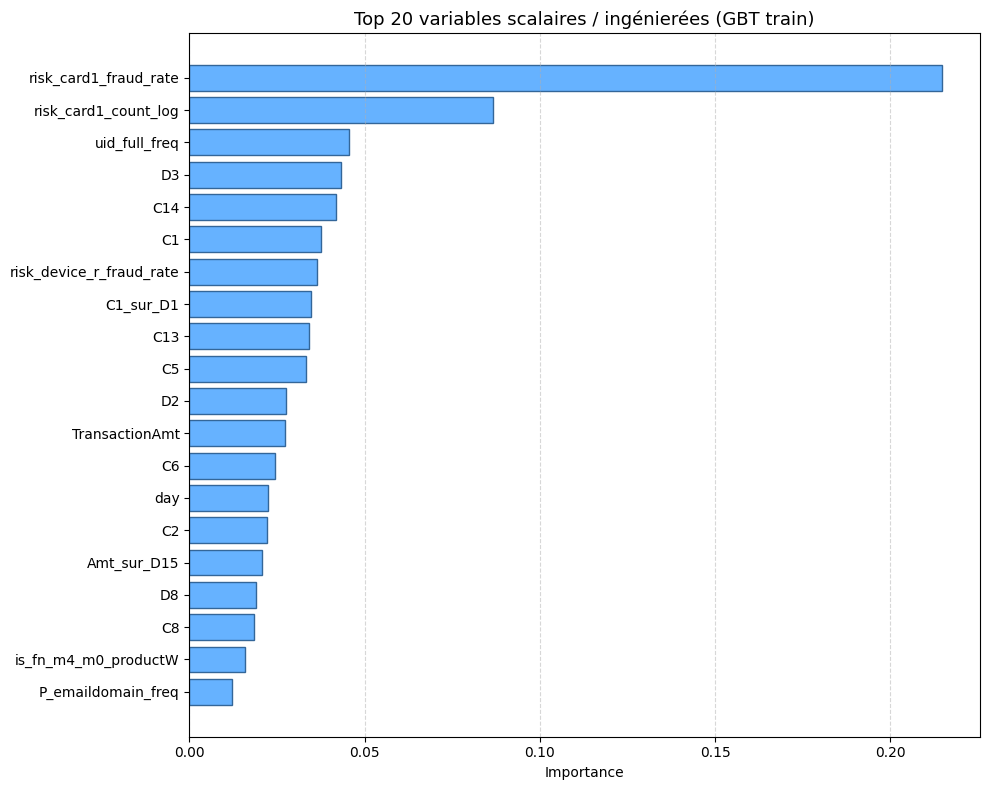

In [8]:
top_20_scalar = scalar_features_sorted[:20]
feature_names = [name for name, _ in top_20_scalar]
importances = [score for _, score in top_20_scalar]

plt.figure(figsize=(10, 8))
plt.barh(feature_names[::-1], importances[::-1], color="#66B2FF", edgecolor="#336699")

plt.xlabel("Importance")
plt.title("Top 20 variables scalaires / ingénierées (GBT train)", fontsize=13)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig((PLOTS_DIR / "top20_scalar_feature_importance.png").as_posix(), bbox_inches="tight")
plt.show()


In [9]:
feat_importance = pd.DataFrame(scalar_features_sorted, columns=["feature", "importance"])
feat_importance["group"] = feat_importance["feature"].str.extract(r"^([a-zA-Z]+)")

grouped_importance = feat_importance.groupby("group")["importance"].sum().sort_values(ascending=False)

print("Importance totale par famille de features scalaires :")
display(grouped_importance)

Importance totale par famille de features scalaires :


group
risk               0.387035
C                  0.280241
D                  0.131684
uid                0.054207
TransactionAmt     0.027397
day                0.022553
is                 0.021836
Amt                0.020743
id                 0.016875
P                  0.012173
log                0.008504
R                  0.005295
card               0.005279
dist               0.002646
addr               0.002197
has                0.000771
M                  0.000372
TransactionHour    0.000191
Name: importance, dtype: float64

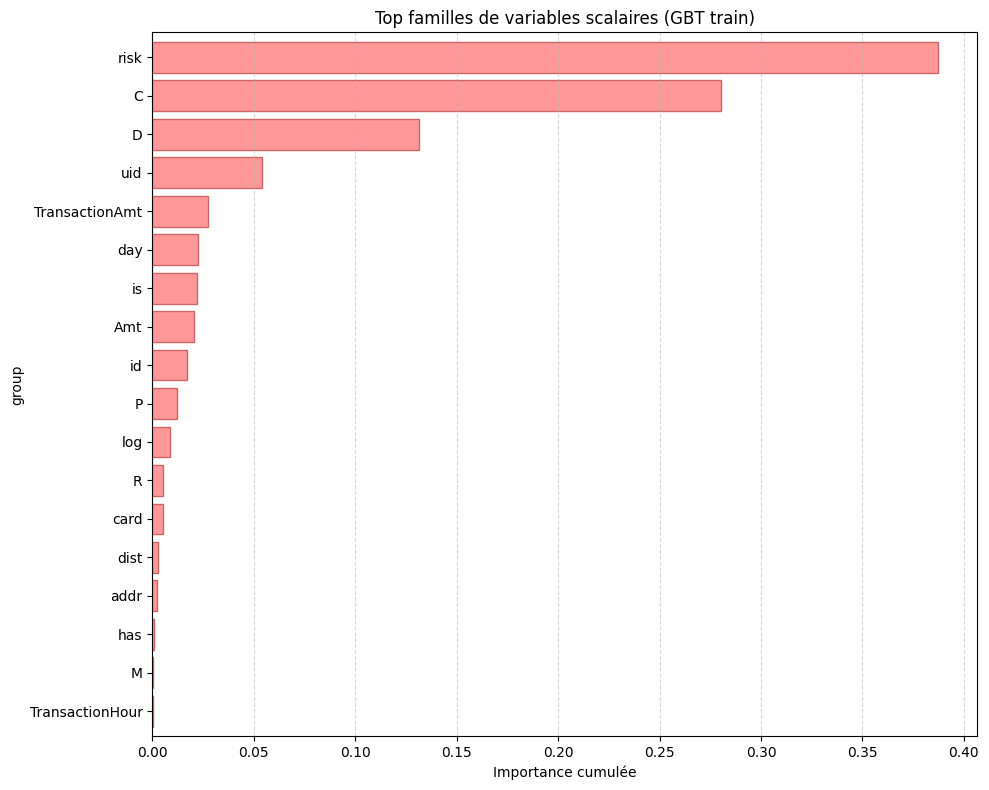

In [10]:
plt.figure(figsize=(10, 8))
ax = grouped_importance.head(20).plot(
    kind="barh",
    color="#FF9999",
    edgecolor="#CC6666",
    width=0.8,)

plt.gca().invert_yaxis()
plt.xlabel("Importance cumulée")
plt.title("Top familles de variables scalaires (GBT train)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig((PLOTS_DIR / "scalar_feature_group_importance.png").as_posix(), bbox_inches="tight")
plt.show()


### 8.1.1 — Lecture des variables ajoutées

On vérifie deux choses :
- leur **importance modèle** dans la vue scalaire/interprétable ;
- pour les flags binaires, leur **fréquence** et leur **taux de fraude** sur `train` et `valid`.

Les variables `risk_*` et `is_fn_*` viennent du notebook 05. Elles ont été créées après l'analyse d'erreurs pour mieux capter les profils de fraudes ratées, notamment autour de `card1`, `ProductCD`, `DeviceType`, `card6`, `R_emaildomain` et `M4`.


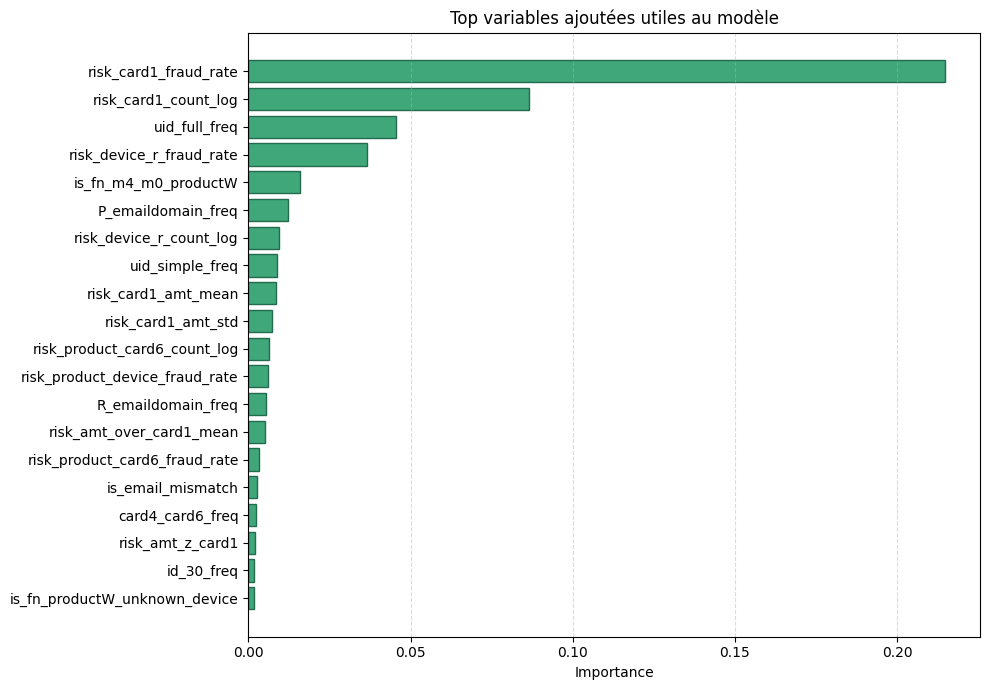

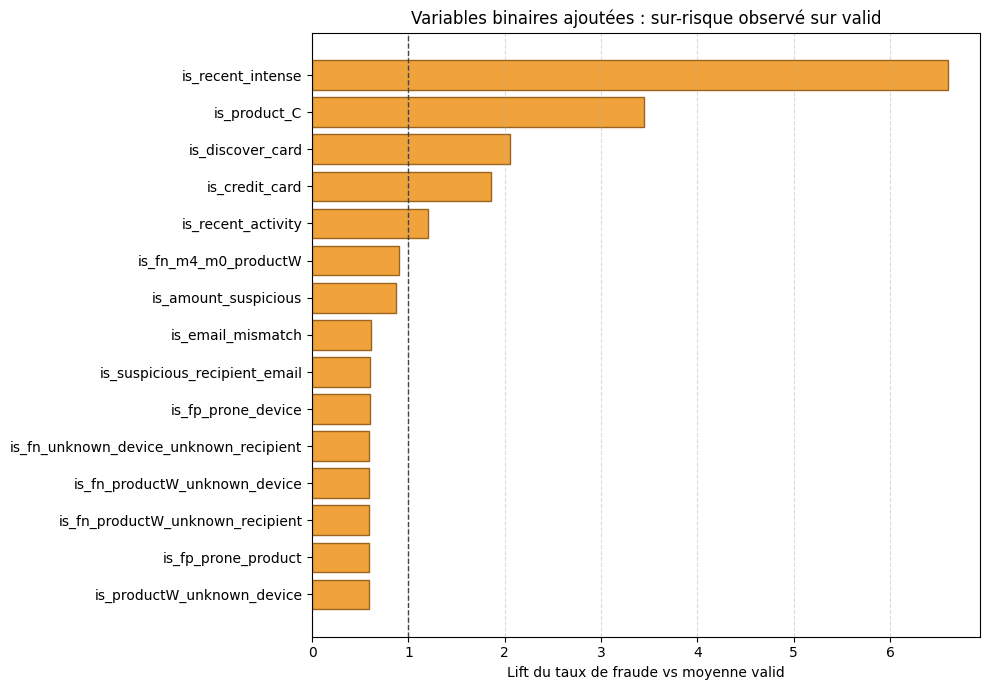

Top variables ajoutées par importance GBT scalaire :


,feature,importance,group,added_family
0,risk_card1_fraud_rate,0.214816,risk,risk_stats_train_only
1,risk_card1_count_log,0.086637,risk,risk_stats_train_only
2,uid_full_freq,0.045517,uid,frequency_encoding
6,risk_device_r_fraud_rate,0.036421,risk,risk_stats_train_only
18,is_fn_m4_m0_productW,0.015973,is,fn_recovery_flags
19,P_emaildomain_freq,0.012173,P,frequency_encoding
23,risk_device_r_count_log,0.009402,risk,risk_stats_train_only
24,uid_simple_freq,0.008691,uid,frequency_encoding
26,risk_card1_amt_mean,0.008567,risk,risk_stats_train_only
30,risk_card1_amt_std,0.007282,risk,risk_stats_train_only


Importance cumulée par famille ajoutée :


,added_family,importance
4,risk_stats_train_only,0.387035
2,frequency_encoding,0.077311
1,fn_recovery_flags,0.019303
3,manual_baseline_flags,0.002533
0,error_pattern_flags,0.000000


Taux de fraude et fréquence des variables binaires ajoutées :


,dataset,feature,family,n_flag_1,share_pct,fraud_rate_pct,global_fraud_rate_pct,lift_vs_global
1,train,is_recent_intense,manual_baseline_flags,7078,1.498,23.269,3.505,6.639
5,train,is_product_C,manual_baseline_flags,55089,11.660,11.619,3.505,3.315
7,train,is_discover_card,manual_baseline_flags,5296,1.121,7.874,3.505,2.247
6,train,is_credit_card,manual_baseline_flags,119283,25.248,6.732,3.505,1.921
0,train,is_recent_activity,manual_baseline_flags,224441,47.505,4.216,3.505,1.203
12,train,is_fn_m4_m0_productW,fn_recovery_flags,148711,31.476,3.249,3.505,0.927
14,train,is_amount_suspicious,error_pattern_flags,97263,20.587,2.900,3.505,0.828
2,train,is_high_amount,manual_baseline_flags,5830,1.234,2.607,3.505,0.744
3,train,is_email_mismatch,manual_baseline_flags,323475,68.467,2.137,3.505,0.610
18,train,is_suspicious_recipient_email,error_pattern_flags,378882,80.195,2.122,3.505,0.605


In [11]:
added_feature_analysis = build_added_feature_analysis(
    train_df=train_df,
    valid_df=valid_df,
    feat_importance=feat_importance,
    feature_selection_dir=FEATURE_SELECTION_DIR,
    plots_dir=PLOTS_DIR,
    metadata_dir=METADATA_DIR,)

added_importance = added_feature_analysis["added_importance"]
added_family_importance = added_feature_analysis["added_family_importance"]
binary_feature_profile = added_feature_analysis["binary_feature_profile"]

print("Top variables ajoutées par importance GBT scalaire :")
display(added_importance.head(25))

print("Importance cumulée par famille ajoutée :")
display(added_family_importance)

print("Taux de fraude et fréquence des variables binaires ajoutées :")
display(binary_feature_profile)

### Sélection des variables `Vxx` par importance et corrélation

On sélectionne les `Vxx` uniquement sur le split `train` pour limiter le risque de fuite d'information.

- Méthode : combinaison `50 %` importance GBT + `50 %` corrélation absolue avec `isFraud`.
- Seuil retenu : `score > 0.011`, sur la même échelle que le protocole historique.
- Résultat du run : `202` vars `Vxx` retenues.
- Lecture : les `Vxx` restent une source majeure de signal, mais la sélection évite de garder aveuglément les `339` variables initiales.

In [ ]:
import builtins

VXX_SCORE_THRESHOLD = 0.011
vxx_cols = [
    c for c in train_df.columns
    if c.startswith("V") and c[1:].isdigit()]

weight_col_v = "classWeight" if "classWeight" in train_df.columns else None
v_select_cols = ["isFraud"] + ([weight_col_v] if weight_col_v else []) + vxx_cols

assembler_v = VectorAssembler(inputCols=vxx_cols, outputCol="v_features")
df_v = assembler_v.transform(train_df.select(*v_select_cols))

gbt_v_params = {
    "labelCol": "isFraud",
    "featuresCol": "v_features",
    "maxIter": 20,
    "seed": 42,}
if weight_col_v:
    gbt_v_params["weightCol"] = weight_col_v

gbt_v = GBTClassifier(**gbt_v_params)
model_v = gbt_v.fit(df_v)
importances_v = model_v.featureImportances.toArray()
vxx_importance = pd.DataFrame({"feature": vxx_cols, "importance": importances_v})

correlation_map = {}
df_corr_input = train_df.select("isFraud", *vxx_cols)
for colname in vxx_cols:
    corr = df_corr_input.stat.corr("isFraud", colname)
    if corr is None or pd.isna(corr):
        corr = 0.0
    correlation_map[colname] = builtins.abs(float(corr))

vxx_importance["correlation"] = vxx_importance["feature"].map(correlation_map).fillna(0.0)

vxx_importance["score"] = 0.5 * vxx_importance["importance"] + 0.5 * vxx_importance["correlation"]
vxx_final = vxx_importance.sort_values("score", ascending=False).reset_index(drop=True)

top_vxx = vxx_final[vxx_final["score"] > VXX_SCORE_THRESHOLD].copy()
top_vxx.to_csv((FEATURE_SELECTION_DIR / "top_vxx_candidates.csv").as_posix(), index=False)

print(f"Vxx candidates : {len(vxx_cols)} | retenues : {len(top_vxx)} | seuil={VXX_SCORE_THRESHOLD}")
display(top_vxx)

Vxx candidates : 339 | retenues : 202 | seuil=0.011


,feature,importance,correlation,score
0,V258,0.115220,0.225465,0.170343
1,V257,0.000151,0.282018,0.141085
2,V201,0.031612,0.248484,0.140048
3,V246,0.000000,0.271629,0.135814
4,V244,0.000000,0.268872,0.134436
...,...,...,...,...
197,V143,0.013401,0.009461,0.011431
198,V162,0.000000,0.022834,0.011417
199,V160,0.003995,0.018835,0.011415
200,V152,0.006384,0.016208,0.011296


## 8.2 — Construction du vecteur final de features

Objectif : assembler un vecteur final robuste en combinant les familles de variables les plus utiles.

- Variables métier et baseline : `log1p_`, `is_`, `has_`, `risk_`, `fp_`, `is_fn_`.
- Variables catégorielles encodées : `*_vec`, `*_freq`, `*_target_enc`.
- Variables `Vxx` retenues par la sélection précédente.
- Exclusion volontaire des colonnes `*_idx`, car elles introduisent un ordre artificiel et doublonnent le One-Hot Encoding.

In [ ]:
top_features_manual = [
    "id_38_vec", "log1p_TransactionAmt", "id_29_vec", "R_emaildomain_freq", "log1p_Amt_sur_D15",
    "is_credit_card", "P_emaildomain_freq", "card6_vec", "card4_vec", "log1p_C1_sur_D1",
    "scaled_features", "id_35_vec", "M1_vec", "DeviceType_vec", "M789_combo_freq", "M3_vec",
    "M4_vec", "id_15_vec", "id_28_vec", "M5_vec", "is_amount_suspicious"]

core_feature_columns = [
    c for c in train_df.columns
    if c.endswith("_vec")
    or c.endswith("_freq")
    or c.endswith("_target_enc")
    or c.startswith("is_")
    or c.startswith("has_")
    or c.startswith("log1p_")
    or c.startswith("fp_")
    or (c.startswith("risk_") and not c.startswith("risk_key_"))
    or c == "scaled_features"]

family_prefixes = [
    "id_",
    "card",
    "P_",
    "R_",]

safe_family_features = [
    c for c, t in train_df.dtypes
    if any(c.startswith(pref) for pref in family_prefixes)
    and t != "string"
    and not c.endswith("_idx")
    and c not in {"isFraud", "classWeight", "features", "features_to_scale"}]

vxx_to_keep = top_vxx["feature"].tolist()

merged = list(dict.fromkeys(
    top_features_manual
    + core_feature_columns
    + safe_family_features
    + vxx_to_keep))
strings_in_df = {c for c, t in train_df.dtypes if t == "string"}
final_features_list = [
    c for c in merged
    if c in train_df.columns
    and c not in strings_in_df
]
missing_requested_features = [c for c in merged if c not in train_df.columns]

print(f"Nombre total de blocs features finaux : {len(final_features_list)}")
print(f"- baseline/core features : {len(core_feature_columns)}")
print(f"- family numeric features : {len(safe_family_features)}")
print(f"- selected Vxx : {len(vxx_to_keep)}")
if missing_requested_features:
    print("Features demandees absentes ignorees :", missing_requested_features[:20])

Nombre total de blocs features finaux : 356
- baseline/core features : 134
- family numeric features : 37
- selected Vxx : 202


In [ ]:
save_json(METADATA_DIR / "final_features_optimized.json", final_features_list)
save_json(
    METADATA_DIR / "optimized_feature_metadata.json",
    {
        "top_features_manual_count": len(top_features_manual),
        "core_feature_columns_count": len(core_feature_columns),
        "safe_family_features_count": len(safe_family_features),
        "selected_vxx_count": len(vxx_to_keep),
        "feature_blocks_count": len(final_features_list),
        "optimized_feature_count": len(final_features_list),
        "missing_requested_features": missing_requested_features,
        "excluded_idx_columns": [c for c in train_df.columns if c.endswith("_idx")],},)
feat_importance.to_csv((FEATURE_SELECTION_DIR / "scalar_feature_importance_full.csv").as_posix(), index=False)
grouped_importance.to_csv((FEATURE_SELECTION_DIR / "scalar_feature_group_importance.csv").as_posix())

### Étape 2 — Assembler les features

In [ ]:
train_final_clean = train_df.drop("features")
valid_final_clean = valid_df.drop("features")

final_assembler = VectorAssembler(
    inputCols=final_features_list,
    outputCol="features")

train_df = final_assembler.transform(train_final_clean)
valid_df = final_assembler.transform(valid_final_clean)
df_final = train_df.unionByName(valid_df)

feature_dimension = (
    train_df
    .select(size(vector_to_array("features")).alias("dimension"))
    .first()["dimension"])
optimized_metadata = load_json(METADATA_DIR / "optimized_feature_metadata.json")
optimized_metadata["feature_vector_dimension"] = int(feature_dimension)
save_json(METADATA_DIR / "optimized_feature_metadata.json", optimized_metadata)

print(f"Blocs d'entree VectorAssembler : {len(final_features_list)}")
print(f"Dimension reelle du vecteur features : {feature_dimension}")

Blocs d'entree VectorAssembler : 356
Dimension reelle du vecteur features : 725


### Synthèse de la sélection finale

La sélection finale garde un espace de features riche, mais contrôlé.

- `356` blocs de features sont assemblés.
- La dimension réelle du vecteur Spark est `725`, car certaines colonnes comme `*_vec` et `scaled_features` sont déjà vectorielles.
- `202` variables `Vxx` sont retenues, avec `0` feature demandée absente.
- Les colonnes `*_idx` sont exclues pour éviter un signal ordinal artificiel.
- Impact : le modèle conserve les signaux forts tout en limitant les doublons et les colonnes peu interprétables.

In [16]:
train_df.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_optimized_train_split.parquet").as_posix())
valid_df.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_optimized_valid_split.parquet").as_posix())
df_final.write.mode("overwrite").parquet((STAGE_DATA_DIR / "train_features_optimized.parquet").as_posix())
print(f"Jeu optimisé sauvegardé dans {STAGE_DATA_DIR}")

Jeu optimisé sauvegardé dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\data


## 8.3 — Tuning du GBT Spark

Objectif : choisir un réglage robuste pour le `GBTClassifier` sans exploser le temps de calcul local.

On teste quelques couples `maxDepth / maxIter` sur un échantillon contrôlé du train/valid. Cette étape ne sert pas encore à déclarer le score final : elle sert à choisir une zone de paramètres raisonnable.

Lecture attendue :
- `maxDepth` trop faible sous-apprend et manque des patterns de fraude ;
- `maxDepth` trop élevé peut améliorer le train mais augmenter le risque de sur-apprentissage ;
- on retient ensuite le meilleur compromis pour réentraîner sur le split complet.


In [17]:
train_small = train_df.sample(fraction=0.4, seed=42).cache()
valid_small = valid_df.sample(fraction=0.5, seed=42).cache()

evaluator_auc = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderROC")
evaluator_pr = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderPR")

depths = [5, 8, 10]
iters = [20, 50, 100]
TUNING_THRESHOLD = 0.4
TUNING_SUBSAMPLING_RATE = 0.98
TUNING_STEP_SIZE = 0.079
TUNING_SEED = 42

results = []

for d in depths:
    for i in iters:
        print(f"Entraînement GBT (maxDepth={d}, maxIter={i})...")
        gbt = GBTClassifier(
            labelCol="isFraud",
            featuresCol="features",
            weightCol="classWeight",
            maxDepth=d,
            maxIter=i,
            subsamplingRate=TUNING_SUBSAMPLING_RATE,
            stepSize=TUNING_STEP_SIZE,
            seed=TUNING_SEED,)
        model = gbt.fit(train_small)

        preds = model.transform(valid_small)
        preds = preds.withColumn("proba_1", vector_to_array("probability")[1])
        preds = preds.withColumn("custom_pred", when(col("proba_1") > TUNING_THRESHOLD, 1).otherwise(0))

        conf_df = preds.groupBy("isFraud", "custom_pred").agg(count("*").alias("n"))
        conf = {(row["isFraud"], row["custom_pred"]): row["n"] for row in conf_df.collect()}

        TP = conf.get((1, 1), 0)
        FP = conf.get((0, 1), 0)
        FN = conf.get((1, 0), 0)
        TN = conf.get((0, 0), 0)

        precision = TP / (TP + FP + 1e-6)
        recall = TP / (TP + FN + 1e-6)
        f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
        accuracy = (TP + TN) / (TP + FP + FN + TN + 1e-6)
        auc = evaluator_auc.evaluate(preds)
        auc_pr = evaluator_pr.evaluate(preds)

        results.append(
            {
                "maxDepth": d,
                "maxIter": i,
                "subsamplingRate": TUNING_SUBSAMPLING_RATE,
                "stepSize": TUNING_STEP_SIZE,
                "seed": TUNING_SEED,
                "threshold": TUNING_THRESHOLD,
                "AUC": round(auc, 4),
                "AUC_PR": round(auc_pr, 4),
                "F1": round(f1, 4),
                "Accuracy": round(accuracy, 4),
                "Precision": round(precision, 4),
                "Recall": round(recall, 4),})

df_results = pd.DataFrame(results)
df_results.to_csv((METRICS_DIR / "tuning_results.csv").as_posix(), index=False)

for row in df_results.to_dict(orient="records"):
    with mlflow.start_run(run_name=f"depth_{row['maxDepth']}_iter_{row['maxIter']}", nested=True):
        mlflow.set_tag("stage", STAGE_NAME)
        run_context = f"tuning depth={int(row['maxDepth'])} iter={int(row['maxIter'])}"
        safe_mlflow_log_params(
            {
                "maxDepth": int(row["maxDepth"]),
                "maxIter": int(row["maxIter"]),
                "subsamplingRate": float(row["subsamplingRate"]),
                "stepSize": float(row["stepSize"]),
                "seed": int(row["seed"]),
                "threshold": float(row["threshold"]),
            },
            context=run_context,)
        safe_mlflow_log_metrics(
            {
                "auc": float(row["AUC"]),
                "auc_pr": float(row["AUC_PR"]),
                "f1": float(row["F1"]),
                "accuracy": float(row["Accuracy"]),
                "precision": float(row["Precision"]),
                "recall": float(row["Recall"]),},
            context=run_context,)

print("\n Résultats tuning GBT (features optimisées, split sans leakage) :")
display(df_results)

train_small.unpersist()
valid_small.unpersist()

Entraînement GBT (maxDepth=5, maxIter=20)...
Entraînement GBT (maxDepth=5, maxIter=50)...
Entraînement GBT (maxDepth=5, maxIter=100)...
Entraînement GBT (maxDepth=8, maxIter=20)...
Entraînement GBT (maxDepth=8, maxIter=50)...
Entraînement GBT (maxDepth=8, maxIter=100)...
Entraînement GBT (maxDepth=10, maxIter=20)...
Entraînement GBT (maxDepth=10, maxIter=50)...
Entraînement GBT (maxDepth=10, maxIter=100)...

 Résultats tuning GBT (features optimisées, split sans leakage) :


,maxDepth,maxIter,subsamplingRate,stepSize,seed,threshold,AUC,AUC_PR,F1,Accuracy,Precision,Recall
0,5,20,0.98,0.079,42,0.4,0.9016,0.4918,0.2423,0.8239,0.1423,0.8142
1,5,50,0.98,0.079,42,0.4,0.9176,0.5509,0.2666,0.8421,0.1588,0.8298
2,5,100,0.98,0.079,42,0.4,0.9273,0.5902,0.2906,0.8588,0.1759,0.8367
3,8,20,0.98,0.079,42,0.4,0.9110,0.5653,0.2930,0.8675,0.1796,0.7936
4,8,50,0.98,0.079,42,0.4,0.9245,0.6301,0.3484,0.8975,0.2232,0.7927
5,8,100,0.98,0.079,42,0.4,0.9318,0.6754,0.4088,0.9216,0.2765,0.7844
6,10,20,0.98,0.079,42,0.4,0.9006,0.5967,0.3197,0.8883,0.2025,0.7589
7,10,50,0.98,0.079,42,0.4,0.9128,0.6552,0.4120,0.9262,0.2843,0.7482
8,10,100,0.98,0.079,42,0.4,0.9162,0.6857,0.5127,0.9515,0.3928,0.7379


DataFrame[uid_full: string, id_31: string, id_30: string, M789_combo: string, card4_card6: string, R_emaildomain: string, P_emaildomain: string, risk_key_device_r: string, risk_key_product_device: string, risk_key_product_card6: string, card1: int, isFraud: int, TransactionDT: int, TransactionAmt: double, ProductCD: string, card2: double, card3: double, card4: string, card5: double, card6: string, addr1: double, addr2: double, dist1: double, C1: double, C2: double, C3: double, C4: double, C5: double, C6: double, C7: double, C8: double, C9: double, C10: double, C11: double, C12: double, C13: double, C14: double, D1: double, D2: double, D3: double, D4: double, D5: double, D6: double, D8: double, D9: double, D10: double, D11: double, D12: double, D13: double, D14: double, D15: double, M1: string, M2: string, M3: string, M4: string, M5: string, M6: string, M7: string, M8: string, M9: string, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9:

In [18]:
train_optimized_path = STAGE_DATA_DIR / "train_features_optimized_train_split.parquet"
valid_optimized_path = STAGE_DATA_DIR / "train_features_optimized_valid_split.parquet"
optimized_path = STAGE_DATA_DIR / "train_features_optimized.parquet"

if "train_df" in locals() and "valid_df" in locals() and "features" in train_df.columns:
    print("Split optimisé déjà présent en mémoire : réutilisation de la version courante.")
    df_final = train_df.unionByName(valid_df)
elif train_optimized_path.exists() and valid_optimized_path.exists():
    print("Chargement du split optimisé depuis le cache stage 07...")
    train_df = spark.read.parquet(train_optimized_path.as_posix())
    valid_df = spark.read.parquet(valid_optimized_path.as_posix())
    df_final = train_df.unionByName(valid_df)
elif optimized_path.exists():
    print("Chargement du dataset optimisé complet depuis le cache stage 07...")
    df_final = spark.read.parquet(optimized_path.as_posix())

print(f"Train rows: {train_df.count()} | Valid rows: {valid_df.count()}")


Split optimisé déjà présent en mémoire : réutilisation de la version courante.
Train rows: 472453 | Valid rows: 118087


In [ ]:
# Lecture du meilleur tuning deja calcule pour eviter un second train lourd

tuning_path = METRICS_DIR / "tuning_results.csv"
if tuning_path.exists():
    tuning_df = pd.read_csv(tuning_path)
    sort_cols = [c for c in ["F1", "AUC_PR", "AUC"] if c in tuning_df.columns]
    tuning_df = tuning_df.sort_values(sort_cols, ascending=False)
    display(tuning_df.head(5))
    print("Reference lue depuis tuning_results.csv pour preserver la RAM locale")
else:
    print("tuning_results.csv introuvable : lance d'abord la cellule de tuning.")


def evaluate_model_light(df, model, dataset_name="valid", threshold=0.825, sample_fraction=None, max_depth=None, max_iter=None):
    evaluator_auc = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderROC")
    evaluator_aucpr = BinaryClassificationEvaluator(labelCol="isFraud", metricName="areaUnderPR")
    eval_df = df
    if sample_fraction is not None:
        eval_df = df.sample(fraction=sample_fraction, seed=42).repartition(4)
    else:
        eval_df = df.repartition(4)

    preds = model.transform(eval_df)
    preds = preds.withColumn("proba_array", vector_to_array("probability")) \
                 .withColumn("proba_1", col("proba_array")[1]) \
                 .withColumn("custom_prediction", when(col("proba_1") > threshold, 1).otherwise(0))

    conf_df = preds.groupBy("isFraud", "custom_prediction").count().collect()
    conf = {(row["isFraud"], row["custom_prediction"]): row["count"] for row in conf_df}

    TP = conf.get((1, 1), 0)
    FP = conf.get((0, 1), 0)
    FN = conf.get((1, 0), 0)
    TN = conf.get((0, 0), 0)

    precision = TP / (TP + FP + 1e-6)
    recall = TP / (TP + FN + 1e-6)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
    accuracy = (TP + TN) / (TP + FP + FN + TN + 1e-6)
    auc = evaluator_auc.evaluate(preds)
    auc_pr = evaluator_aucpr.evaluate(preds)

    return {
        "Model": "GBT",
        "Dataset": dataset_name,
        "maxDepth": max_depth,
        "maxIter": max_iter,
        "Threshold": threshold,
        "AUC": auc,
        "AUC_PR": auc_pr,
        "F1": f1,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,}

,maxDepth,maxIter,subsamplingRate,stepSize,seed,threshold,AUC,AUC_PR,F1,Accuracy,Precision,Recall
8,10,100,0.98,0.079,42,0.4,0.9162,0.6857,0.5127,0.9515,0.3928,0.7379
7,10,50,0.98,0.079,42,0.4,0.9128,0.6552,0.4120,0.9262,0.2843,0.7482
5,8,100,0.98,0.079,42,0.4,0.9318,0.6754,0.4088,0.9216,0.2765,0.7844
4,8,50,0.98,0.079,42,0.4,0.9245,0.6301,0.3484,0.8975,0.2232,0.7927
6,10,20,0.98,0.079,42,0.4,0.9006,0.5967,0.3197,0.8883,0.2025,0.7589


Reference lue depuis tuning_results.csv pour preserver la RAM locale


In [ ]:
best_gbt = GBTClassifier(
    featuresCol="features",
    labelCol="isFraud",
    weightCol="classWeight",
    maxDepth=10,
    maxIter=100,
    subsamplingRate=0.98,
    stepSize=0.079,
    seed=42,)

train_fit_df = train_df.repartition(4).persist(StorageLevel.DISK_ONLY)
valid_fit_df = valid_df.repartition(4).persist(StorageLevel.DISK_ONLY)
train_fit_df.count()
valid_fit_df.count()

print("Réentraînement du modèle final GBT sans leakage (maxDepth=10, maxIter=100)")
best_model = best_gbt.fit(train_fit_df)

model_path = (MODELS_STAGE_DIR / "gbt_final_model").as_posix()
best_model.write().overwrite().save(model_path)
save_json(METADATA_DIR / "final_model_path.json", {"model_path": model_path})

results_final = []
train_metrics = evaluate_model_light(train_fit_df, best_model, dataset_name="train", threshold=0.825, sample_fraction=0.03, max_depth=10, max_iter=100)
train_metrics["EvaluationScope"] = "sample_3pct"
results_final.append(train_metrics)

valid_metrics = evaluate_model_light(valid_fit_df, best_model, dataset_name="valid", threshold=0.825, sample_fraction=None, max_depth=10, max_iter=100)
valid_metrics["EvaluationScope"] = "full_validation"
results_final.append(valid_metrics)

results_df = pd.DataFrame(results_final)
results_df.to_csv((METRICS_DIR / "final_model_metrics.csv").as_posix(), index=False)

valid_row = results_df[results_df["Dataset"] == "valid"].iloc[0]
safe_mlflow_log_params(
    {
        "final_maxDepth": 10,
        "final_maxIter": 100,
        "final_threshold": 0.825,
        "final_subsamplingRate": 0.98,
        "final_stepSize": 0.079,
        "final_seed": 42,
        "final_train_metric_scope": "sample_3pct",
        "final_valid_metric_scope": "full_validation",
        "training_scope": "train_split_only_no_leakage",},
    context="final metrics",)
safe_mlflow_log_metrics(
    {
        "final_valid_auc": float(valid_row["AUC"]),
        "final_valid_auc_pr": float(valid_row["AUC_PR"]),
        "final_valid_f1": float(valid_row["F1"]),
        "final_valid_accuracy": float(valid_row["Accuracy"]),
        "final_valid_precision": float(valid_row["Precision"]),
        "final_valid_recall": float(valid_row["Recall"]),},
    context="final metrics",)

display(results_df)

train_fit_df.unpersist()
valid_fit_df.unpersist()

Réentraînement du modèle final GBT sans leakage (maxDepth=10, maxIter=100)


,Model,Dataset,maxDepth,maxIter,Threshold,AUC,AUC_PR,F1,Accuracy,Precision,Recall,EvaluationScope
0,GBT,train,10,100,0.825,0.997568,0.948668,0.866593,0.991507,0.889140,0.845161,sample_3pct
1,GBT,valid,10,100,0.825,0.950399,0.763001,0.721571,0.982479,0.806073,0.653106,full_validation


DataFrame[uid_full: string, id_31: string, id_30: string, M789_combo: string, card4_card6: string, R_emaildomain: string, P_emaildomain: string, risk_key_device_r: string, risk_key_product_device: string, risk_key_product_card6: string, card1: int, isFraud: int, TransactionDT: int, TransactionAmt: double, ProductCD: string, card2: double, card3: double, card4: string, card5: double, card6: string, addr1: double, addr2: double, dist1: double, C1: double, C2: double, C3: double, C4: double, C5: double, C6: double, C7: double, C8: double, C9: double, C10: double, C11: double, C12: double, C13: double, C14: double, D1: double, D2: double, D3: double, D4: double, D5: double, D6: double, D8: double, D9: double, D10: double, D11: double, D12: double, D13: double, D14: double, D15: double, M1: string, M2: string, M3: string, M4: string, M5: string, M6: string, M7: string, M8: string, M9: string, V1: double, V2: double, V3: double, V4: double, V5: double, V6: double, V7: double, V8: double, V9:

### Interprétation des résultats

Le GBT brut reste une base solide, mais son rappel reste le point faible.

- Sur `valid` complet : `F1 = 0.7216`, `Precision = 0.8061`, `Recall = 0.6531`.
- La précision est élevée : quand le modèle prédit fraude, il se trompe relativement peu.
- Le rappel reste limité : environ `35 %` des fraudes de validation ne sont pas récupérées à ce seuil.
- Conclusion : le modèle brut est propre, mais il faut optimiser seuil, pondération et blend pour récupérer plus de fraudes.

## 8.4 — Optimisation du seuil et calibration isotonique 

Cette section  évalue jusqu’où on peut aller **sans réentraîner le modèle** : on garde le GBT brut, puis on teste plusieurs seuils et une calibration isotonique.

La question est la suivante : le rappel limité provient-il simplement du seuil de décision, ou faut-il réellement modifier le modèle pour mieux détecter les fraudes manquées ?

**Protocole de calibration séparé :**

1. Les probabilités sont extraites une seule fois sur `valid_df`.
2. Le jeu de validation est séparé aléatoirement en deux moitiés stratifiées :
   - `calib` : choix du seuil et apprentissage de la calibration ;
   - `hold` : évaluation séparée des choix effectués.
3. Les probabilités brutes et les probabilités calibrées par régression isotonique sont comparées.
4. La cible est `Precision ≥ 0.70` et `Recall ≥ 0.70`. Si elle n’est pas atteinte, le meilleur `F1` est conservé comme diagnostic.
5. Les résultats sont sauvegardés en `CSV` et `JSON`.

Cette section sert de référence pour la suite. Si un modèle pondéré ou un blend fait mieux, il sera retenu à la place.

In [21]:
preds_valid_for_threshold = (
    best_model.transform(valid_df)
    .withColumn("proba_array", vector_to_array("probability"))
    .withColumn("proba_1", col("proba_array")[1])
    .select("isFraud", "proba_1")
)
valid_scores = safe_to_pandas(preds_valid_for_threshold, context="valid threshold scores")
valid_scores["isFraud"] = valid_scores["isFraud"].astype(int)
print(f"Scores valid collectés : shape={valid_scores.shape} | fraud_rate={valid_scores['isFraud'].mean():.4f}")


[Spark->Pandas] valid threshold scores: shape=(118087, 2)
Scores valid collectés : shape=(118087, 2) | fraud_rate=0.0348


In [22]:
calib_df, hold_df = train_test_split(
    valid_scores,
    test_size=0.5,
    stratify=valid_scores["isFraud"],
    random_state=42,)

print(
    f"calib={len(calib_df)} (fraud={calib_df['isFraud'].mean():.4f}) | "
    f"hold={len(hold_df)} (fraud={hold_df['isFraud'].mean():.4f})")


def sweep_thresholds(scores, labels, lo=0.05, hi=0.99, step=0.005):
    rows = []
    n = len(labels)
    for t in np.arange(lo, hi + 1e-9, step):
        pred = (scores > t).astype(int)
        TP = int(((pred == 1) & (labels == 1)).sum())
        FP = int(((pred == 1) & (labels == 0)).sum())
        FN = int(((pred == 0) & (labels == 1)).sum())
        TN = int(((pred == 0) & (labels == 0)).sum())
        precision = TP / (TP + FP + 1e-9)
        recall = TP / (TP + FN + 1e-9)
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        accuracy = (TP + TN) / (n if n > 0 else 1)
        rows.append(
            {
                "threshold": float(t),
                "F1": f1,
                "Precision": precision,
                "Recall": recall,
                "Accuracy": accuracy,
                "TP": TP,
                "FP": FP,
                "FN": FN,
                "TN": TN,})
    return pd.DataFrame(rows)


def pick_best(sweep_df):
    mask = (sweep_df["Precision"] >= 0.70) & (sweep_df["Recall"] >= 0.70)
    if mask.any():
        best = sweep_df[mask].sort_values("F1", ascending=False).iloc[0]
        return best, "constrained P>=0.70 & R>=0.70"
    best = sweep_df.sort_values("F1", ascending=False).iloc[0]
    return best, "fallback: best F1 (constraint not reachable)"

raw_sweep = sweep_thresholds(calib_df["proba_1"].values, calib_df["isFraud"].values)
raw_sweep.to_csv((METRICS_DIR / "threshold_sweep_raw_calib.csv").as_posix(), index=False)
raw_best, raw_strategy = pick_best(raw_sweep)
print(
    f"[RAW] threshold={raw_best['threshold']:.3f} | F1={raw_best['F1']:.4f} | "
    f"P={raw_best['Precision']:.4f} | R={raw_best['Recall']:.4f} | strategy={raw_strategy}")


calib=59043 (fraud=0.0348) | hold=59044 (fraud=0.0348)
[RAW] threshold=0.755 | F1=0.7066 | P=0.7096 | R=0.7037 | strategy=constrained P>=0.70 & R>=0.70


In [23]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
iso.fit(calib_df["proba_1"].values, calib_df["isFraud"].values)

calib_df = calib_df.assign(proba_cal=iso.transform(calib_df["proba_1"].values))
hold_df = hold_df.assign(proba_cal=iso.transform(hold_df["proba_1"].values))

cal_sweep = sweep_thresholds(calib_df["proba_cal"].values, calib_df["isFraud"].values)
cal_sweep.to_csv((METRICS_DIR / "threshold_sweep_calibrated_calib.csv").as_posix(), index=False)
cal_best, cal_strategy = pick_best(cal_sweep)
print(
    f"[CALIBRATED] threshold={cal_best['threshold']:.3f} | F1={cal_best['F1']:.4f} | "
    f"P={cal_best['Precision']:.4f} | R={cal_best['Recall']:.4f} | strategy={cal_strategy}")

joblib.dump(iso, (METADATA_DIR / "isotonic_calibrator.joblib").as_posix())
save_json(
    METADATA_DIR / "thresholds.json",
    {
        "raw_best_threshold": float(raw_best["threshold"]),
        "raw_strategy": raw_strategy,
        "calibrated_best_threshold": float(cal_best["threshold"]),
        "calibrated_strategy": cal_strategy,
        "isotonic_calibrator_path": (METADATA_DIR / "isotonic_calibrator.joblib").as_posix(),
        "selection_set": "stratified 50% of valid (calib half), seed=42",
    },
)


[CALIBRATED] threshold=0.245 | F1=0.7086 | P=0.7151 | R=0.7022 | strategy=constrained P>=0.70 & R>=0.70


,variant,threshold,AUC,AUC_PR,F1,Precision,Recall,Accuracy,TP,FP,FN,TN
0,baseline_threshold_0.825,0.825,0.948216,0.758924,0.725061,0.814702,0.653190,0.982776,1341,305,712,56686
1,raw_optimal,0.755,0.948216,0.758924,0.706897,0.714998,0.698977,0.979846,1435,572,618,56419
2,calibrated_optimal,0.245,0.948216,0.758924,0.707890,0.719095,0.697029,0.979998,1431,559,622,56432



Meilleure variante : baseline_threshold_0.825 | threshold=0.825 | F1=0.7251 | P=0.8147 | R=0.6532 | AUC=0.9482 | AUC_PR=0.7589


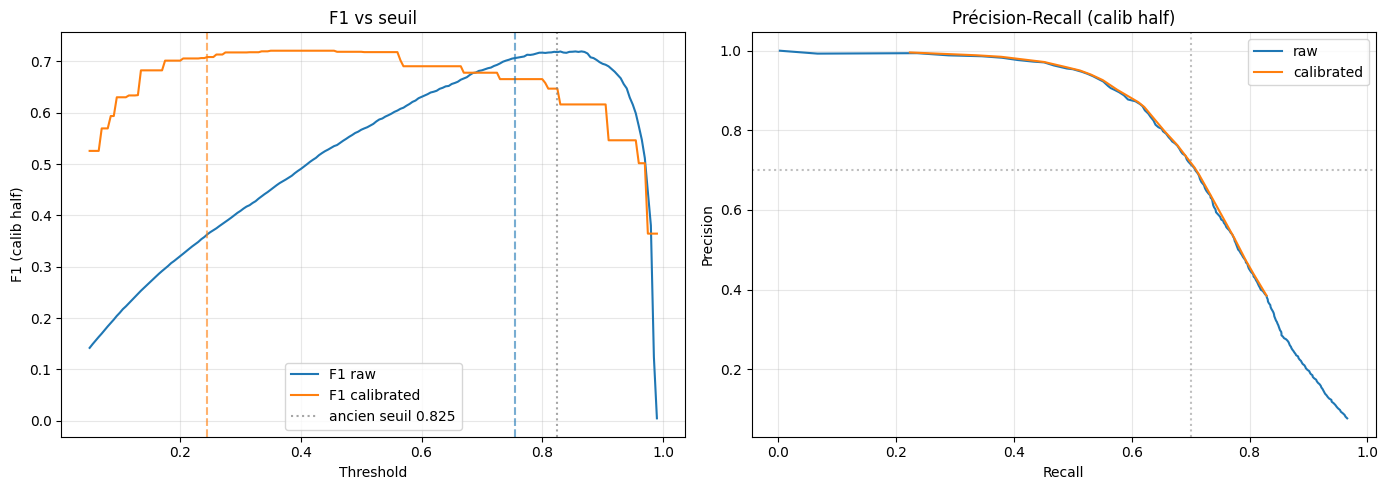

In [24]:
def metrics_at(scores, labels, t):
    pred = (scores > t).astype(int)
    TP = int(((pred == 1) & (labels == 1)).sum())
    FP = int(((pred == 1) & (labels == 0)).sum())
    FN = int(((pred == 0) & (labels == 1)).sum())
    TN = int(((pred == 0) & (labels == 0)).sum())
    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    n_labels = len(labels)
    accuracy = (TP + TN) / (n_labels if n_labels > 0 else 1)
    return {
        "F1": f1,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,}


hold_auc = roc_auc_score(hold_df["isFraud"], hold_df["proba_1"])
hold_aucpr = average_precision_score(hold_df["isFraud"], hold_df["proba_1"])

eval_rows = [
    {
        "variant": "baseline_threshold_0.825",
        "threshold": 0.825,
        "AUC": hold_auc,
        "AUC_PR": hold_aucpr,
        **metrics_at(hold_df["proba_1"].values, hold_df["isFraud"].values, 0.825),
    },
    {
        "variant": "raw_optimal",
        "threshold": float(raw_best["threshold"]),
        "AUC": hold_auc,
        "AUC_PR": hold_aucpr,
        **metrics_at(hold_df["proba_1"].values, hold_df["isFraud"].values, float(raw_best["threshold"])),
    },
    {
        "variant": "calibrated_optimal",
        "threshold": float(cal_best["threshold"]),
        "AUC": hold_auc,
        "AUC_PR": hold_aucpr,
        **metrics_at(hold_df["proba_cal"].values, hold_df["isFraud"].values, float(cal_best["threshold"])),
    },
]
threshold_eval_df = pd.DataFrame(eval_rows)
threshold_eval_df.to_csv((METRICS_DIR / "threshold_eval_holdout.csv").as_posix(), index=False)
display(threshold_eval_df)

best_variant = threshold_eval_df.sort_values("F1", ascending=False).iloc[0]
print(
    f"\nMeilleure variante : {best_variant['variant']} | threshold={best_variant['threshold']:.3f} | "
    f"F1={best_variant['F1']:.4f} | P={best_variant['Precision']:.4f} | R={best_variant['Recall']:.4f} | "
    f"AUC={best_variant['AUC']:.4f} | AUC_PR={best_variant['AUC_PR']:.4f}")

save_json(
    METADATA_DIR / "threshold_best_variant.json",
    {
        "variant": str(best_variant["variant"]),
        "threshold": float(best_variant["threshold"]),
        "F1": float(best_variant["F1"]),
        "Precision": float(best_variant["Precision"]),
        "Recall": float(best_variant["Recall"]),
        "AUC": float(best_variant["AUC"]),
        "AUC_PR": float(best_variant["AUC_PR"]),
        "raw_strategy": raw_strategy,
        "calibrated_strategy": cal_strategy,
    },)

safe_mlflow_log_params(
    {
        "threshold_raw_best": float(raw_best["threshold"]),
        "threshold_calibrated_best": float(cal_best["threshold"]),
        "threshold_selection_rule": "max F1 with P>=0.70 & R>=0.70",
    },
    context="threshold holdout selection",)
safe_mlflow_log_metrics(
    {
        "holdout_auc": float(hold_auc),
        "holdout_auc_pr": float(hold_aucpr),
        "holdout_f1_baseline_0p825": float(threshold_eval_df.iloc[0]["F1"]),
        "holdout_recall_baseline_0p825": float(threshold_eval_df.iloc[0]["Recall"]),
        "holdout_f1_raw_opt": float(threshold_eval_df.iloc[1]["F1"]),
        "holdout_recall_raw_opt": float(threshold_eval_df.iloc[1]["Recall"]),
        "holdout_precision_raw_opt": float(threshold_eval_df.iloc[1]["Precision"]),
        "holdout_f1_cal_opt": float(threshold_eval_df.iloc[2]["F1"]),
        "holdout_recall_cal_opt": float(threshold_eval_df.iloc[2]["Recall"]),
        "holdout_precision_cal_opt": float(threshold_eval_df.iloc[2]["Precision"]),
    },
    context="threshold holdout selection",)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(raw_sweep["threshold"], raw_sweep["F1"], label="F1 raw", color="#1f77b4")
ax[0].plot(cal_sweep["threshold"], cal_sweep["F1"], label="F1 calibrated", color="#ff7f0e")
ax[0].axvline(raw_best["threshold"], color="#1f77b4", linestyle="--", alpha=0.6)
ax[0].axvline(cal_best["threshold"], color="#ff7f0e", linestyle="--", alpha=0.6)
ax[0].axvline(0.825, color="grey", linestyle=":", alpha=0.7, label="ancien seuil 0.825")
ax[0].set_xlabel("Threshold")
ax[0].set_ylabel("F1 (calib half)")
ax[0].set_title("F1 vs seuil")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(raw_sweep["Recall"], raw_sweep["Precision"], label="raw", color="#1f77b4")
ax[1].plot(cal_sweep["Recall"], cal_sweep["Precision"], label="calibrated", color="#ff7f0e")
ax[1].axhline(0.70, color="grey", linestyle=":", alpha=0.5)
ax[1].axvline(0.70, color="grey", linestyle=":", alpha=0.5)
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Précision-Recall (calib half)")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()

plt.savefig((PLOTS_DIR / "threshold_sweep_and_pr.png").as_posix(), bbox_inches="tight")
plt.show()

In [25]:
iso_prod = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
iso_prod.fit(valid_scores["proba_1"].values, valid_scores["isFraud"].values)
joblib.dump(iso_prod, (METADATA_DIR / "isotonic_calibrator_prod.joblib").as_posix())

valid_scores_cal = iso_prod.transform(valid_scores["proba_1"].values)

production_threshold = float(cal_best["threshold"]) if best_variant["variant"] == "calibrated_optimal" else float(raw_best["threshold"])
production_uses_calibration = best_variant["variant"] == "calibrated_optimal"

if production_uses_calibration:
    full_scores = valid_scores_cal
else:
    full_scores = valid_scores["proba_1"].values

full_metrics = metrics_at(full_scores, valid_scores["isFraud"].values, production_threshold)
full_metrics["AUC"] = roc_auc_score(valid_scores["isFraud"], valid_scores["proba_1"])
full_metrics["AUC_PR"] = average_precision_score(valid_scores["isFraud"], valid_scores["proba_1"])
full_metrics["threshold"] = production_threshold
full_metrics["calibrated"] = production_uses_calibration
full_metrics["dataset"] = "valid_full"

final_full_df = pd.DataFrame([full_metrics])
final_full_df.to_csv((METRICS_DIR / "final_model_metrics_full_valid_optimized.csv").as_posix(), index=False)
display(final_full_df)

save_json(
    METADATA_DIR / "production_scoring_config.json",
    {
        "calibrator_path": (METADATA_DIR / "isotonic_calibrator_prod.joblib").as_posix(),
        "threshold": production_threshold,
        "use_calibration": production_uses_calibration,
        "fitted_on": "full valid (no leakage on train)",
        "selection_rule": "max F1 with P>=0.70 & R>=0.70 on calib half",
    },)

safe_mlflow_log_metrics(
    {
        "valid_full_optimized_f1": float(full_metrics["F1"]),
        "valid_full_optimized_precision": float(full_metrics["Precision"]),
        "valid_full_optimized_recall": float(full_metrics["Recall"]),
        "valid_full_optimized_auc": float(full_metrics["AUC"]),
        "valid_full_optimized_auc_pr": float(full_metrics["AUC_PR"]),
    },
    context="optimized full-valid threshold report",)

print(
    f"\nConfig production sauvegardée. threshold={production_threshold:.3f} | "
    f"calibration={'OUI' if production_uses_calibration else 'NON'}")


,F1,Precision,Recall,Accuracy,TP,FP,FN,TN,AUC,AUC_PR,threshold,calibrated,dataset
0,0.706763,0.712271,0.70134,0.979769,2879,1163,1226,112819,0.950405,0.76296,0.755,False,valid_full



Config production sauvegardée. threshold=0.755 | calibration=NON


### Interprétation du seuil et de la calibration

Le simple réglage du seuil améliore le rappel, mais ne suffit pas à améliorer le compromis global.

- Seuil historique `0.825` : `F1 = 0.7251`, `Precision = 0.8147`, `Recall = 0.6532`.
- Seuil brut optimisé `0.755` : rappel plus haut (`0.6990`), mais précision plus basse (`0.7150`).
- Calibration isotonique : résultat proche (`F1 = 0.7079`, `Precision = 0.7191`, `Recall = 0.6970`).
- Conclusion : baisser le seuil récupère des fraudes, mais ajoute trop de faux positifs. Il faut donc passer aux variantes pondérées et au blend.

## 8.5 — Renforcement contrôlé du poids des fraudes

Après 8.4, on sait que le seuil/calibration seul ne suffit pas à récupérer assez de fraudes sans perdre trop de précision.

Ici on teste deux variantes du même GBT Spark, en augmentant légèrement le poids de la classe fraude :
- `x1.15` : version prudente, censée augmenter le rappel sans trop créer de faux positifs ;
- `x1.30` : version plus agressive, utile seulement si le gain de rappel compense la perte de précision/F1.

La décision se fait sur le `holdout` issu du valid split 50/50. Le `full_valid` sert ensuite de lecture globale.


In [ ]:
if "sweep_thresholds" not in globals() or "metrics_at" not in globals():
    raise ValueError("Lance d abord la section 8.5 jusqu aux cellules de sweep/calibration.")

# limite le run local on tet 2 vals
RECALL_WEIGHT_MULTIPLIERS = [1.15, 1.30]

def pick_threshold_for_70_goal(sweep_df, min_precision=0.70, min_recall=0.70):
    feasible = sweep_df[(sweep_df["Precision"] >= min_precision) & (sweep_df["Recall"] >= min_recall)]
    if len(feasible) > 0:
        return feasible.sort_values("F1", ascending=False).iloc[0], "hit_precision_recall_70"

    precision_floor = sweep_df[sweep_df["Precision"] >= min_precision]
    if len(precision_floor) > 0:
        return precision_floor.sort_values(["Recall", "F1"], ascending=False).iloc[0], "max_recall_with_precision_70"

    return sweep_df.sort_values("F1", ascending=False).iloc[0], "fallback_best_f1"

def evaluate_scores_at_threshold(scores_df, threshold):
    metrics = metrics_at(scores_df["proba_1"].values, scores_df["isFraud"].values, float(threshold))
    metrics["AUC"] = roc_auc_score(scores_df["isFraud"], scores_df["proba_1"])
    metrics["AUC_PR"] = average_precision_score(scores_df["isFraud"], scores_df["proba_1"])
    return metrics

valid_weight_eval_df = valid_df

candidate_rows = []
candidate_models = {}

for multiplier in RECALL_WEIGHT_MULTIPLIERS:
    weight_col = f"classWeight_recall_x{str(multiplier).replace('.', 'p')}"
    model_variant = f"gbt_classWeight_x{multiplier:.2f}"
    print(f"\nEntrainement candidat {model_variant}...")

    train_weight_df = train_df.withColumn(
        weight_col,
        when(col("isFraud") == 1, col("classWeight") * float(multiplier)).otherwise(col("classWeight")),)

    recall_gbt = GBTClassifier(
        featuresCol="features",
        labelCol="isFraud",
        weightCol=weight_col,
        maxDepth=10,
        maxIter=100,
        subsamplingRate=0.98,
        stepSize=0.079,
        seed=42,)
    recall_model = recall_gbt.fit(train_weight_df)
    candidate_models[model_variant] = recall_model

    candidate_scores = (
        recall_model.transform(valid_weight_eval_df)
        .withColumn("proba_array", vector_to_array("probability"))
        .withColumn("proba_1", col("proba_array")[1])
        .select("isFraud", "proba_1"))
    candidate_scores = safe_to_pandas(candidate_scores, context=f"candidate {model_variant}")
    candidate_scores["isFraud"] = candidate_scores["isFraud"].astype(int)

    cand_calib_df, cand_hold_df = train_test_split(
        candidate_scores,
        test_size=0.5,
        stratify=candidate_scores["isFraud"],
        random_state=42,)
    cand_sweep = sweep_thresholds(cand_calib_df["proba_1"].values, cand_calib_df["isFraud"].values)
    cand_sweep["model_variant"] = model_variant
    cand_sweep.to_csv((METRICS_DIR / f"threshold_sweep_{model_variant}_calib.csv").as_posix(), index=False)

    selected_threshold, selection_rule = pick_threshold_for_70_goal(cand_sweep)
    threshold = float(selected_threshold["threshold"])

    for scope, scores_df in [("holdout", cand_hold_df), ("full_valid", candidate_scores)]:
        metrics = evaluate_scores_at_threshold(scores_df, threshold)
        metrics.update(
            {
                "model_variant": model_variant,
                "weight_multiplier": float(multiplier),
                "threshold": threshold,
                "selection_rule": selection_rule,
                "scope": scope,
            })
        candidate_rows.append(metrics)


recall_weight_candidates_df = pd.DataFrame(candidate_rows)
recall_weight_candidates_df.to_csv((METRICS_DIR / "recall_weight_candidates.csv").as_posix(), index=False)
display_cols = [
    "model_variant",
    "scope",
    "weight_multiplier",
    "threshold",
    "selection_rule",
    "F1",
    "Precision",
    "Recall",
    "TP",
    "FP",
    "FN",
    "TN",
    "AUC",
    "AUC_PR",]
display(recall_weight_candidates_df[display_cols].sort_values(["scope", "F1"], ascending=[True, False]))

holdout_rows = recall_weight_candidates_df[recall_weight_candidates_df["scope"] == "holdout"].copy()
hit_rows = holdout_rows[(holdout_rows["Precision"] >= 0.70) & (holdout_rows["Recall"] >= 0.70)]
if len(hit_rows) > 0:
    selected_candidate = hit_rows.sort_values("F1", ascending=False).iloc[0]
elif (holdout_rows["Precision"] >= 0.70).any():
    selected_candidate = holdout_rows[holdout_rows["Precision"] >= 0.70].sort_values(["Recall", "F1"], ascending=False).iloc[0]
else:
    selected_candidate = holdout_rows.sort_values("F1", ascending=False).iloc[0]

selected_variant = str(selected_candidate["model_variant"])
saved_candidate_model_paths = {}
for model_variant, candidate_model in candidate_models.items():
    candidate_path = (MODELS_STAGE_DIR / model_variant).as_posix()
    candidate_model.write().overwrite().save(candidate_path)
    saved_candidate_model_paths[model_variant] = candidate_path

selected_model_path = saved_candidate_model_paths[selected_variant]

save_json(
    METADATA_DIR / "recall_weight_candidate_selection.json",
    {
        "selected_variant": selected_variant,
        "selected_model_path": selected_model_path,
        "saved_candidate_model_paths": saved_candidate_model_paths,
        "weight_multiplier": float(selected_candidate["weight_multiplier"]),
        "threshold": float(selected_candidate["threshold"]),
        "selection_rule": str(selected_candidate["selection_rule"]),
        "holdout_F1": float(selected_candidate["F1"]),
        "holdout_Precision": float(selected_candidate["Precision"]),
        "holdout_Recall": float(selected_candidate["Recall"]),
    },)

print(
    f"\nCandidat retenu: {selected_variant} | threshold={float(selected_candidate['threshold']):.3f} | "
    f"F1={float(selected_candidate['F1']):.4f} | P={float(selected_candidate['Precision']):.4f} | "
    f"R={float(selected_candidate['Recall']):.4f}")



Entrainement candidat gbt_classWeight_x1.15...
[Spark->Pandas] candidate gbt_classWeight_x1.15: shape=(118087, 2)

Entrainement candidat gbt_classWeight_x1.30...
[Spark->Pandas] candidate gbt_classWeight_x1.30: shape=(118087, 2)


,model_variant,scope,weight_multiplier,threshold,selection_rule,F1,Precision,Recall,TP,FP,FN,TN,AUC,AUC_PR
1,gbt_classWeight_x1.15,full_valid,1.15,0.785,hit_precision_recall_70,0.715705,0.739605,0.693301,2846,1002,1259,112980,0.947479,0.760777
3,gbt_classWeight_x1.30,full_valid,1.30,0.795,max_recall_with_precision_70,0.697383,0.703520,0.691352,2838,1196,1267,112786,0.949038,0.756535
0,gbt_classWeight_x1.15,holdout,1.15,0.785,hit_precision_recall_70,0.715704,0.749467,0.684851,1406,470,647,56521,0.943460,0.753625
2,gbt_classWeight_x1.30,holdout,1.30,0.795,max_recall_with_precision_70,0.693255,0.700846,0.685826,1408,601,645,56390,0.946153,0.751701



Candidat retenu: gbt_classWeight_x1.30 | threshold=0.795 | F1=0.6933 | P=0.7008 | R=0.6858


### Interprétation classWeight

La pondération des fraudes aide, mais aucune variante seule ne dépasse clairement le modèle final.

- `x1.15` est le meilleur candidat individuel : `F1 = 0.7157`, `Precision = 0.7495`, `Recall = 0.6849`.
- `x1.30` augmente légèrement le rappel par rapport à `x1.15`, mais baisse le F1 (`0.6933`).
- La variante `x1.30` reste utile, car elle apporte un signal différent que le blend peut exploiter.
- Conclusion : les modèles pondérés ne remplacent pas le GBT brut, mais ils enrichissent le futur blend.

## 8.6 — Blend de probabilités entre deux GBT Spark

Le GBT de base garde une bonne précision, tandis que la variante `classWeight × 1.15` détecte davantage de fraudes.

Au lieu de choisir un seul des deux modèles, on combine leurs probabilités :

`proba_finale = (1 - alpha) * proba_GBT_base + alpha * proba_GBT_recall`

- `alpha = 0` : seul le GBT de base est utilisé ;
- `alpha = 1` : seul le GBT orienté rappel est utilisé ;
- une valeur intermédiaire permet de rechercher un compromis entre précision et rappel.

Chaque valeur de `alpha` est testée avec un seuil adapté, choisi sur la partie `calib` puis évalué sur le `holdout`.

In [ ]:
if "sweep_thresholds" not in globals() or "metrics_at" not in globals():
    raise ValueError("Lance d abord la section 8.5 pour definir sweep_thresholds et metrics_at.")
if "best_model" not in globals():
    raise ValueError("best_model absent : relance le reentrainement final du notebook 07 avant cette cellule.")

selection_path = METADATA_DIR / "recall_weight_candidate_selection.json"
if not selection_path.exists():
    raise ValueError("Lance d abord la cellule classWeight x1.15/x1.30 pour creer recall_weight_candidate_selection.json.")

with open(selection_path, "r", encoding="utf-8") as f:
    recall_selection = json.load(f)

selected_variant = recall_selection["selected_variant"]
selected_model_path = recall_selection["selected_model_path"]

if "candidate_models" in globals() and selected_variant in candidate_models:
    recall_weight_model = candidate_models[selected_variant]
else:
    recall_weight_model = GBTClassificationModel.load(selected_model_path)

def with_named_outputs(model, suffix):
    return model.copy(
        {
            model.rawPredictionCol: f"rawPrediction_{suffix}",
            model.probabilityCol: f"probability_{suffix}",
            model.predictionCol: f"prediction_{suffix}",})

base_named = with_named_outputs(best_model, "base")
recall_named = with_named_outputs(recall_weight_model, "recall")

blend_scores_spark = (
    recall_named.transform(base_named.transform(valid_df))
    .withColumn("proba_base_array", vector_to_array("probability_base"))
    .withColumn("proba_recall_array", vector_to_array("probability_recall"))
    .select(
        "isFraud",
        col("proba_base_array")[1].alias("proba_base"),
        col("proba_recall_array")[1].alias("proba_recall"),))

blend_scores = safe_to_pandas(blend_scores_spark, context="blend scores")
blend_scores["isFraud"] = blend_scores["isFraud"].astype(int)
print(f"Scores blend collectes : shape={blend_scores.shape} | fraud_rate={blend_scores['isFraud'].mean():.4f}")

if "pick_threshold_for_70_goal" not in globals():
    def pick_threshold_for_70_goal(sweep_df, min_precision=0.70, min_recall=0.70):
        feasible = sweep_df[(sweep_df["Precision"] >= min_precision) & (sweep_df["Recall"] >= min_recall)]
        if len(feasible) > 0:
            return feasible.sort_values("F1", ascending=False).iloc[0], "hit_precision_recall_70"
        precision_floor = sweep_df[sweep_df["Precision"] >= min_precision]
        if len(precision_floor) > 0:
            return precision_floor.sort_values(["Recall", "F1"], ascending=False).iloc[0], "max_recall_with_precision_70"
        return sweep_df.sort_values("F1", ascending=False).iloc[0], "fallback_best_f1"

def evaluate_blend_scores(scores_df, proba_col, threshold):
    metrics = metrics_at(scores_df[proba_col].values, scores_df["isFraud"].values, float(threshold))
    metrics["AUC"] = roc_auc_score(scores_df["isFraud"], scores_df[proba_col])
    metrics["AUC_PR"] = average_precision_score(scores_df["isFraud"], scores_df[proba_col])
    return metrics

BLEND_ALPHAS = np.round(np.linspace(0.0, 1.0, 11), 2)
blend_rows = []
all_blend_sweeps = []

for alpha in BLEND_ALPHAS:
    proba_col = f"proba_blend_{alpha:.2f}"
    blend_scores[proba_col] = (1 - alpha) * blend_scores["proba_base"] + alpha * blend_scores["proba_recall"]

    blend_calib_df, blend_hold_df = train_test_split(
        blend_scores[["isFraud", proba_col]],
        test_size=0.5,
        stratify=blend_scores["isFraud"],
        random_state=42,)

    sweep = sweep_thresholds(blend_calib_df[proba_col].values, blend_calib_df["isFraud"].values)
    sweep["blend_alpha_recall"] = float(alpha)
    all_blend_sweeps.append(sweep)

    selected_threshold, selection_rule = pick_threshold_for_70_goal(sweep)
    threshold = float(selected_threshold["threshold"])

    for scope, scores_df in [("holdout", blend_hold_df), ("full_valid", blend_scores[["isFraud", proba_col]])]:
        metrics = evaluate_blend_scores(scores_df, proba_col, threshold)
        metrics.update(
            {
                "blend_alpha_recall": float(alpha),
                "threshold": threshold,
                "selection_rule": selection_rule,
                "scope": scope,})
        blend_rows.append(metrics)

blend_candidates_df = pd.DataFrame(blend_rows)
blend_sweep_df = pd.concat(all_blend_sweeps, ignore_index=True)

blend_candidates_df.to_csv((METRICS_DIR / "blend_probability_candidates.csv").as_posix(), index=False)
blend_sweep_df.to_csv((METRICS_DIR / "blend_probability_threshold_sweeps.csv").as_posix(), index=False)

blend_display_cols = [
    "scope",
    "blend_alpha_recall",
    "threshold",
    "selection_rule",
    "F1",
    "Precision",
    "Recall",
    "TP",
    "FP",
    "FN",
    "TN",
    "AUC",
    "AUC_PR",]
display(blend_candidates_df[blend_display_cols].sort_values(["scope", "F1"], ascending=[True, False]))

holdout_blends = blend_candidates_df[blend_candidates_df["scope"] == "holdout"].copy()
blend_hits = holdout_blends[(holdout_blends["Precision"] >= 0.70) & (holdout_blends["Recall"] >= 0.70)]
if len(blend_hits) > 0:
    selected_blend = blend_hits.sort_values("F1", ascending=False).iloc[0]
    blend_selection_note = "hit_precision_recall_70"
else:
    precision_floor = holdout_blends[holdout_blends["Precision"] >= 0.70]
    if len(precision_floor) > 0:
        selected_blend = precision_floor.sort_values(["Recall", "F1"], ascending=False).iloc[0]
        blend_selection_note = "best_recall_with_precision_70"
    else:
        selected_blend = holdout_blends.sort_values("F1", ascending=False).iloc[0]
        blend_selection_note = "fallback_best_f1"

selected_full_valid = blend_candidates_df[
    (blend_candidates_df["scope"] == "full_valid")
    & (blend_candidates_df["blend_alpha_recall"] == selected_blend["blend_alpha_recall"])
    & (blend_candidates_df["threshold"] == selected_blend["threshold"])
].iloc[0]

save_json(
    METADATA_DIR / "blend_probability_candidate_selection.json",
    {
        "selection_note": blend_selection_note,
        "base_model": "gbt_final_model",
        "recall_model": selected_variant,
        "blend_alpha_recall": float(selected_blend["blend_alpha_recall"]),
        "blend_formula": "proba = (1 - alpha) * proba_base + alpha * proba_recall_weight",
        "threshold": float(selected_blend["threshold"]),
        "holdout_F1": float(selected_blend["F1"]),
        "holdout_Precision": float(selected_blend["Precision"]),
        "holdout_Recall": float(selected_blend["Recall"]),
        "full_valid_F1": float(selected_full_valid["F1"]),
        "full_valid_Precision": float(selected_full_valid["Precision"]),
        "full_valid_Recall": float(selected_full_valid["Recall"]),},)

print(
    f"Blend retenu: alpha_recall={float(selected_blend['blend_alpha_recall']):.2f} | "
    f"threshold={float(selected_blend['threshold']):.3f} | "
    f"holdout F1={float(selected_blend['F1']):.4f} P={float(selected_blend['Precision']):.4f} R={float(selected_blend['Recall']):.4f} | "
    f"full_valid F1={float(selected_full_valid['F1']):.4f} P={float(selected_full_valid['Precision']):.4f} R={float(selected_full_valid['Recall']):.4f}")


[Spark->Pandas] blend scores: shape=(118087, 3)
Scores blend collectes : shape=(118087, 3) | fraud_rate=0.0348


,scope,blend_alpha_recall,threshold,selection_rule,F1,Precision,Recall,TP,FP,FN,TN,AUC,AUC_PR
5,full_valid,0.2,0.755,hit_precision_recall_70,0.719749,0.741602,0.699147,2870,1000,1235,112982,0.954908,0.771876
7,full_valid,0.3,0.750,hit_precision_recall_70,0.716694,0.735143,0.699147,2870,1034,1235,112948,0.955556,0.773946
9,full_valid,0.4,0.745,hit_precision_recall_70,0.715564,0.730642,0.701096,2878,1061,1227,112921,0.955804,0.775085
15,full_valid,0.7,0.765,hit_precision_recall_70,0.714304,0.734431,0.695250,2854,1032,1251,112950,0.954577,0.772315
3,full_valid,0.1,0.755,hit_precision_recall_70,0.714037,0.728517,0.700122,2874,1071,1231,112911,0.953631,0.768562
11,full_valid,0.5,0.750,hit_precision_recall_70,0.712592,0.730553,0.695493,2855,1053,1250,112929,0.955716,0.775268
17,full_valid,0.8,0.770,hit_precision_recall_70,0.711907,0.726719,0.697686,2864,1077,1241,112905,0.953477,0.769162
13,full_valid,0.6,0.750,hit_precision_recall_70,0.711139,0.722767,0.699878,2873,1102,1232,112880,0.955310,0.774344
1,full_valid,0.0,0.755,hit_precision_recall_70,0.706763,0.712271,0.701340,2879,1163,1226,112819,0.950405,0.762960
19,full_valid,0.9,0.775,hit_precision_recall_70,0.703849,0.708364,0.699391,2871,1182,1234,112800,0.951826,0.764475


Blend retenu: alpha_recall=0.00 | threshold=0.755 | holdout F1=0.7069 P=0.7150 R=0.6990 | full_valid F1=0.7068 P=0.7123 R=0.7013


### Interprétation des résultats du blend 2-way

Le blend 2-way améliore le compromis par rapport aux variantes pondérées seules, mais reste juste sous l'objectif de rappel.

- Meilleur holdout : `alpha = 0.20`, seuil `0.755`.
- Résultat holdout : `F1 = 0.7211`, `Precision = 0.7469`, `Recall = 0.6970`.
- Sur `full_valid` : `F1 = 0.7197`, `Precision = 0.7416`, `Recall = 0.6991`.
- Conclusion : le blend 2-way est stable, mais le rappel reste trop proche de la limite. La recherche 3-way est donc justifiée.

## 8.7 — Blend maximum (recherche 3-way sur les 3 GBT Spark)

Objectif : pousser le blend Spark **au maximum** en exploitant les **3 GBT déjà entraînés** (`gbt_final_model`, `gbt_classWeight_x1.15`, `gbt_classWeight_x1.30`).

on ne réentraîne aucun modèle : elle recharge les 3 modèles sauvegardés, compare les probabilités brutes et calibrées, puis cherche directement la meilleure combinaison 3-way.

Ce qu’on cherche :
- meilleur `F1` avec la contrainte `F1 >= 0.72`, `Precision` dans la fenêtre `0.73-0.75` et `Recall >= 0.70` ;
- choix du seuil sur une moitié `calib`, puis validation sur `holdout`.

Ce qu’on teste :
- **2 familles** de probas : brutes vs isotone-calibrées par modèle ;
- **grid 3-way** `(w_base, w_x1.15, w_x1.30)`, somme = 1, pas = 0.05 ;
- **sweep fin de seuil** au pas `0.002` dans `[0.05, 0.95]`.

La configuration retenue **écrase** `blend_probability_candidate_selection.json` afin que les diagnostics finaux et le notebook 08 utilisent automatiquement le meilleur blend 3-way.


In [ ]:
# === BLEND_MAX_3WAY_V2 ===
#  blend maximum 3-way
best_model, loaded_variants, model_paths = load_three_way_blend_models(MODELS_STAGE_DIR)
print(f"[Reload] best_model chargé : {model_paths['base_path']}")
for model_name, model_path in model_paths["variant_paths"].items():
    print(f"[Reload] {model_name} chargé : {model_path}")
print("GBT prêts :", ["gbt_final_model"] + list(loaded_variants.keys()))


[Reload] best_model chargé : C:/Users/El-fahad COMBO/Desktop/Fraud_Detection_IEEE/models/07_gbt_tuning_final_model/gbt_final_model
[Reload] gbt_classWeight_x1.15 chargé : C:/Users/El-fahad COMBO/Desktop/Fraud_Detection_IEEE/models/07_gbt_tuning_final_model/gbt_classWeight_x1.15
[Reload] gbt_classWeight_x1.30 chargé : C:/Users/El-fahad COMBO/Desktop/Fraud_Detection_IEEE/models/07_gbt_tuning_final_model/gbt_classWeight_x1.30
GBT prêts : ['gbt_final_model', 'gbt_classWeight_x1.15', 'gbt_classWeight_x1.30']


In [ ]:
#  Scoring 3-way sur valid_df 
valid_df = spark.read.parquet((STAGE_DATA_DIR / "train_features_optimized_valid_split.parquet").as_posix())
scores3 = score_three_way_blend_models(valid_df, best_model, loaded_variants, safe_to_pandas)
print(f"Scores 3-way : shape={scores3.shape} | fraud_rate={scores3['isFraud'].mean():.4f}")


[Spark->Pandas] blend max 3-way scores: shape=(118087, 4)
Scores 3-way : shape=(118087, 4) | fraud_rate=0.0348


In [ ]:
# Recherche du meilleur blend 3-way
blend_search = search_best_three_way_blend(
    scores3,
    grid_step=0.05,
    target_p=0.74,
    min_f1=0.72,
    min_p=0.73,
    max_p=0.75,
    min_r=0.70,
    fb_min_p=0.72,
    fb_min_r=0.70,
    random_state=42,)

scores3 = blend_search["scores3"]
all_blend_sweeps = blend_search["all_blend_sweeps"]
best = blend_search["best"]
bl_conf = blend_search["blend_config"]

print(
    f"Configurations 3-way : {blend_search['weights_count']} x 2 familles (raw/cal) x {blend_search['threshold_count']} seuils")
print("Top 5 Blends tries par F1 holdout :")
display(all_blend_sweeps.sort_values(["ideal_pass", "hold_pass", "hold_F1"], ascending=[False, False, False]).head(5))

print("\n=== MEILLEUR BLEND 3-WAY TROUVÉ ===")
for key, value in best.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

blend_path = METRICS_DIR / "blend_probability_candidate_selection.json"
save_json(blend_path, bl_conf)
print(f"\nConfiguration exportée -> {blend_path}")


Configurations 3-way : 231 x 2 familles (raw/cal) x 451 seuils
Top 5 Blends tries par F1 holdout :


,family,w_base,w_x1.15,w_x1.30,threshold,cal_strat,cal_F1,cal_P,cal_R,hold_F1,hold_P,hold_R,hold_TP,hold_FP,hold_FN,hold_pass,ideal_pass
314,cal,0.20,0.25,0.55,0.224,soft_fallback,0.718127,0.734216,0.702729,0.733284,0.748731,0.718461,1475,495,578,1,1
330,cal,0.25,0.20,0.55,0.224,soft_fallback,0.718928,0.732188,0.706140,0.731877,0.746329,0.717974,1474,501,579,1,1
323,cal,0.20,0.70,0.10,0.228,soft_fallback,0.716633,0.732688,0.701267,0.731805,0.749362,0.715051,1468,491,585,1,1
344,cal,0.30,0.10,0.60,0.224,soft_fallback,0.716915,0.732215,0.702242,0.731247,0.746072,0.717000,1472,501,581,1,1
339,cal,0.25,0.65,0.10,0.228,soft_fallback,0.719920,0.737973,0.702729,0.731086,0.750000,0.713103,1464,488,589,1,1



=== MEILLEUR BLEND 3-WAY TROUVÉ ===
  family: cal
  w_base: 0.2000
  w_x1.15: 0.2500
  w_x1.30: 0.5500
  threshold: 0.2240
  cal_strat: soft_fallback
  cal_F1: 0.7181
  cal_P: 0.7342
  cal_R: 0.7027
  hold_F1: 0.7333
  hold_P: 0.7487
  hold_R: 0.7185
  hold_TP: 1475
  hold_FP: 495
  hold_FN: 578
  hold_pass: 1
  ideal_pass: 1

Configuration exportée -> C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\metrics\blend_probability_candidate_selection.json


In [ ]:
# -----------------------------------------------------------------------
# exporte la config 3-way pour les diagnostics
# -----------------------------------------------------------------------
metadata_blend = save_three_way_blend_metadata(
    best=best,
    metadata_dir=METADATA_DIR,
    recall_selection_path=METADATA_DIR / "recall_weight_candidate_selection.json",
)
print(
    "[METADATA_DIR] Blend 3-way mis à jour -> "
    f"family={metadata_blend['strategy']} | "
    f"w=({metadata_blend['w_base']:.2f}, {metadata_blend['w_x1.15']:.2f}, {metadata_blend['w_x1.30']:.2f}) | "
    f"threshold={metadata_blend['threshold']:.4f}"
)


[METADATA_DIR] Blend 3-way mis à jour -> family=cal | w=(0.20, 0.25, 0.55) | threshold=0.2240


In [ ]:
import json

feat_path = METADATA_DIR / "final_features_optimized.json"
if not feat_path.exists():
    raise ValueError("final_features_optimized.json introuvable. Relance la cellule 8.2.")

with open(feat_path, "r") as f:
    final_features_list_check = json.load(f)

all_valid_cols = set(valid_df.columns)
feat_set = set(final_features_list_check)
total = len(final_features_list_check)

print(f"{'='*65}")
print(f"  FEATURES DANS LE MODELE BLEND : {total} variables")
print(f"  COLONNES DANS valid_df        : {len(all_valid_cols)} colonnes")
print(f"{'='*65}")

families_def = [
    ("V (Vxx)",              lambda c: c.startswith("V") and len(c) >= 2 and c[1:].split("_")[0].isdigit()),
    ("fp_ (fingerprint)",    lambda c: c.startswith("fp_")),
    ("uid / uuid",           lambda c: "uid" in c.lower() or "uuid" in c.lower()),
    ("is_fn_ (fn recovery)", lambda c: c.startswith("is_fn_")),
    ("id_ (id features)",    lambda c: c.startswith("id_") and not c.endswith("_idx")),
    ("risk_ (risk flags)",   lambda c: c.startswith("risk_")),
    ("is_ (binary flags)",   lambda c: c.startswith("is_") and not c.startswith("is_fn_")),
    ("has_ (binary flags)",  lambda c: c.startswith("has_")),
    ("log1p_",               lambda c: c.startswith("log1p_")),
    ("_freq",                lambda c: c.endswith("_freq")),
    ("_vec (OHE)",           lambda c: c.endswith("_vec")),
    ("scaled_features",      lambda c: c == "scaled_features"),
    ("card",                 lambda c: c.startswith("card") and not c.endswith("_idx")),
    ("C (C1-C14)",           lambda c: c.startswith("C") and c[1:].isdigit()),
    ("D (D1-D15)",           lambda c: c.startswith("D") and c[1:].isdigit()),
    ("M (M1-M9)",            lambda c: c.startswith("M") and c[1:].isdigit()),]

for fam_name, fn in families_def:
    in_model = sorted([c for c in final_features_list_check if fn(c)])
    if in_model:
        exemples = ", ".join(in_model[:4])
        print(f"\n  {fam_name:<25} : {len(in_model):>3} features")
        print(f"    ex: {exemples}")

print(f"\n{'='*65}")
print("  COLONNES valid_df HORS MODELE (patterns cles)")
print("  Si une colonne importante manque, le modele ne l'a pas vue.")
print(f"{'='*65}")

patterns_a_verifier = [
    "fp_", "uid", "uuid", "is_fn_", "is_intense",
    "M789", "amt_", "ratio_", "device", "browser"]
found_any = False
for pat in patterns_a_verifier:
    dans_valid = sorted([c for c in all_valid_cols if pat.lower() in c.lower()])
    if not dans_valid:
        continue
    found_any = True
    dans_modele = [c for c in dans_valid if c in feat_set]
    hors_modele = [c for c in dans_valid if c not in feat_set]
    print(f"\n  Pattern '{pat}':")
    print(f"    Dans valid_df  ({len(dans_valid):>2}) : {dans_valid[:6]}")
    print(f"    Dans modele    ({len(dans_modele):>2}) : {dans_modele[:6] if dans_modele else 'aucune'}")
    if hors_modele:
        print(f"    [HORS modele]  ({len(hors_modele):>2}) : {hors_modele[:6]}")

if not found_any:
    print("  Aucun pattern trouve dans valid_df.")
print(f"\n{'='*65}")
print("  MODELES DU BLEND")
print(f"{'='*65}")
blend_conf_path = METADATA_DIR / "blend_probability_candidate_selection.json"
with open(blend_conf_path, "r") as f:
    bconf = json.load(f)

for key in ["base_model", "recall_model_x1.15", "recall_model_x1.30"]:
    model_name = bconf.get(key, "?")
    ok = (MODELS_STAGE_DIR / model_name).exists()
    print(f"  {'OK    ' if ok else 'ABSENT'}  {key} = {model_name}")

print(f"\n  Formule  : {bconf.get('blend_formula', 'N/A')}")
print(f"  Famille  : {bconf.get('strategy', 'N/A')}")
print(f"  Seuil    : {bconf.get('threshold', 'N/A')}")
print(f"  Holdout  F1={bconf.get('holdout_F1', 0):.4f} | P={bconf.get('holdout_Precision', 0):.4f} | R={bconf.get('holdout_Recall', 0):.4f}")


  FEATURES DANS LE MODELE BLEND : 356 variables
  COLONNES DANS valid_df        : 589 colonnes

  V (Vxx)                   : 202 features
    ex: V10, V108, V109, V11

  uid / uuid                :   2 features
    ex: uid_full_freq, uid_simple_freq

  is_fn_ (fn recovery)      :   6 features
    ex: is_fn_debit_unknown_device, is_fn_debit_unknown_recipient, is_fn_m4_m0_productW, is_fn_productW_unknown_device

  id_ (id features)         :  27 features
    ex: id_01, id_02, id_03, id_04

  risk_ (risk flags)        :  12 features
    ex: risk_amt_over_card1_mean, risk_amt_z_card1, risk_card1_amt_mean, risk_card1_amt_std

  is_ (binary flags)        :  18 features
    ex: is_amount_suspicious, is_credit_card, is_debit_unknown_device, is_discover_card

  has_ (binary flags)       :  62 features
    ex: has_D12, has_D13, has_D14, has_D6

  log1p_                    :   7 features
    ex: log1p_Amt_sur_D15, log1p_C1_sur_D1, log1p_D1, log1p_D15

  _freq                     :   8 features
 

### Conclusion de l'optimisation finale (Blend 3-way)

Le blend 3-way est la meilleure configuration finale du notebook.

- Configuration retenue : famille `cal`, poids `(base=0.20, x1.15=0.25, x1.30=0.55)`.
- Seuil final : `0.224`.
- Sur holdout : `F1 = 0.7333`, `Precision = 0.7487`, `Recall = 0.7185`.
- Impact : le modèle dépasse la cible `F1 > 0.72`, reste dans la zone de précision `0.73-0.75` et garde un rappel supérieur à `0.70`.
- Conclusion : on garde ce blend comme prédicteur final 

### Diagnostics finaux du blend Spark retenu

Les métriques suivantes reconstruisent le vrai blend final côté Spark sur `full_valid`.

- `AUC = 0.9569` et `AUC_PR = 0.7824` : la séparation globale reste forte.
- `F1 = 0.7257`, `Precision = 0.7415`, `Recall = 0.7106`.
- Volume : `2917` fraudes détectées, `1017` faux positifs et `1188` fraudes manquées.
- Lecture : le holdout choisit le blend, puis `full_valid` confirme que le rappel reste au-dessus de `0.70`

In [ ]:
# === BLEND_MAX_CELL48_PATCH_V4 ===
from sklearn.metrics import precision_recall_curve, roc_curve

blend_selection = load_json(METADATA_DIR / "blend_probability_candidate_selection.json")
score_frame = scores3 if "scores3" in globals() else None
final_blend_scores, final_blend_metrics_df = compute_three_way_blend_diagnostics(
    blend_selection=blend_selection,
    scores3=score_frame,
    spark=spark,
    models_stage_dir=MODELS_STAGE_DIR,
    valid_path=STAGE_DATA_DIR / "train_features_optimized_valid_split.parquet",
    safe_to_pandas_func=safe_to_pandas,
    random_state=42,)

final_blend_metrics = final_blend_metrics_df.iloc[0].to_dict()
final_blend_threshold = float(final_blend_metrics["threshold"])
y_true_blend = final_blend_scores["isFraud"].values.astype(int)
y_score_blend = final_blend_scores["proba_blend"].values

print(
    "[Diagnostics] Vrai blend final -> "
    f"family={final_blend_metrics['family']} | "
    f"w=({final_blend_metrics['w_base']:.2f}, {final_blend_metrics['w_x1.15']:.2f}, {final_blend_metrics['w_x1.30']:.2f}) | "
    f"threshold={final_blend_threshold:.4f}")

save_json(
    METADATA_DIR / "final_blend_curve_config.json",
    {
        "family": final_blend_metrics["family"],
        "w_base": float(final_blend_metrics["w_base"]),
        "w_x1.15": float(final_blend_metrics["w_x1.15"]),
        "w_x1.30": float(final_blend_metrics["w_x1.30"]),
        "blend_alpha_recall": float(final_blend_metrics["blend_alpha_recall"]),
        "threshold": final_blend_threshold,
        "metrics_source": "valid_full_rebuilt_3way",
        "roc_plot": (PLOTS_DIR / "roc_final_blend.png").as_posix(),
        "pr_plot": (PLOTS_DIR / "pr_final_blend.png").as_posix(),
        "threshold_plot": (PLOTS_DIR / "threshold_final_blend.png").as_posix(),},)

final_blend_metrics_df.to_csv((METRICS_DIR / "final_blend_curve_metrics.csv").as_posix(), index=False)

display(final_blend_metrics_df[["family", "w_base", "w_x1.15", "w_x1.30", "blend_alpha_recall", "threshold", "AUC", "AUC_PR", "F1", "Precision", "Recall", "TP", "FP", "FN", "TN"]])


[Diagnostics] Vrai blend final -> family=cal | w=(0.20, 0.25, 0.55) | threshold=0.2240


,family,w_base,w_x1.15,w_x1.30,blend_alpha_recall,threshold,AUC,AUC_PR,F1,Precision,Recall,TP,FP,FN,TN
0,cal,0.2,0.25,0.55,0.8,0.224,0.95694,0.782426,0.725712,0.741484,0.710597,2917,1017,1188,112965


#### ROC du blend final

Cette courbe vérifie la capacité globale du blend à séparer les fraudes des transactions normales.


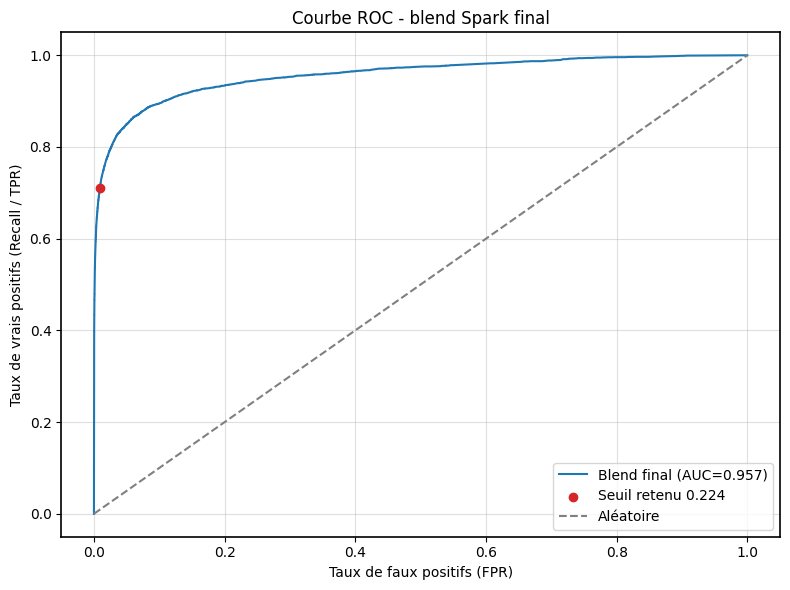

In [39]:
fpr, tpr, _ = roc_curve(y_true_blend, y_score_blend)
roc_auc = final_blend_metrics["AUC"]
selected_fpr = final_blend_metrics["FP"] / (final_blend_metrics["FP"] + final_blend_metrics["TN"] + 1e-9)
selected_tpr = final_blend_metrics["Recall"]

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="#1f77b4", label=f"Blend final (AUC={roc_auc:.3f})")
plt.scatter(selected_fpr, selected_tpr, color="#d62728", zorder=5, label=f"Seuil retenu {final_blend_threshold:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Aléatoire")
plt.title("Courbe ROC - blend Spark final")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (Recall / TPR)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.4)

for spine in plt.gca().spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig((PLOTS_DIR / "roc_final_blend.png").as_posix(), bbox_inches="tight")
plt.show()


#### Courbe précision-rappel du blend final

C'est la courbe la plus importante ici, car les fraudes sont rares. Elle montre directement le compromis entre fausses alertes et fraudes récupérées.


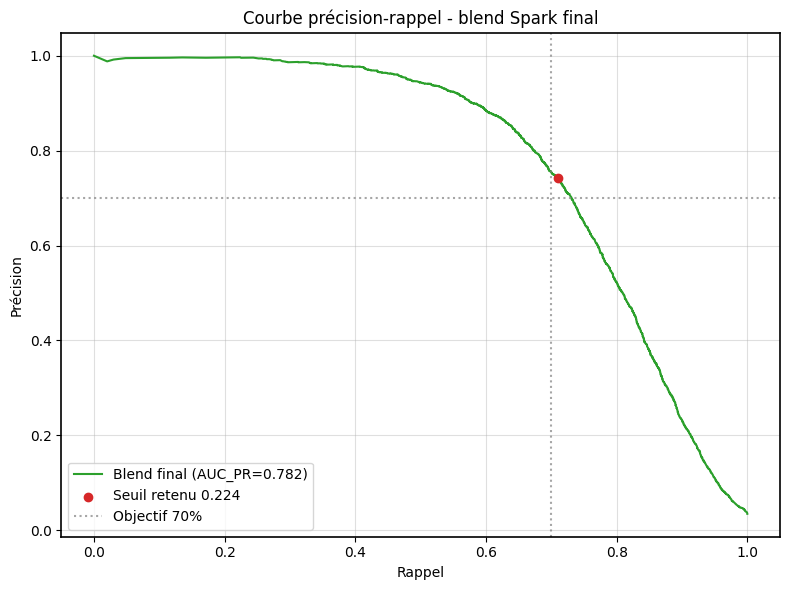

In [40]:
precision_curve, recall_curve, _ = precision_recall_curve(y_true_blend, y_score_blend)
auc_pr = final_blend_metrics["AUC_PR"]

plt.figure(figsize=(8, 6))
plt.plot(recall_curve, precision_curve, color="#2ca02c", label=f"Blend final (AUC_PR={auc_pr:.3f})")
plt.scatter(final_blend_metrics["Recall"], final_blend_metrics["Precision"], color="#d62728", zorder=5, label=f"Seuil retenu {final_blend_threshold:.3f}")
plt.axhline(0.70, color="grey", linestyle=":", alpha=0.7, label="Objectif 70%")
plt.axvline(0.70, color="grey", linestyle=":", alpha=0.7)
plt.title("Courbe précision-rappel - blend Spark final")
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.4)

for spine in plt.gca().spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig((PLOTS_DIR / "pr_final_blend.png").as_posix(), bbox_inches="tight")
plt.show()


#### Choix du seuil final

Cette courbe montre comment évoluent F1, précision et rappel quand on change le seuil du blend final.


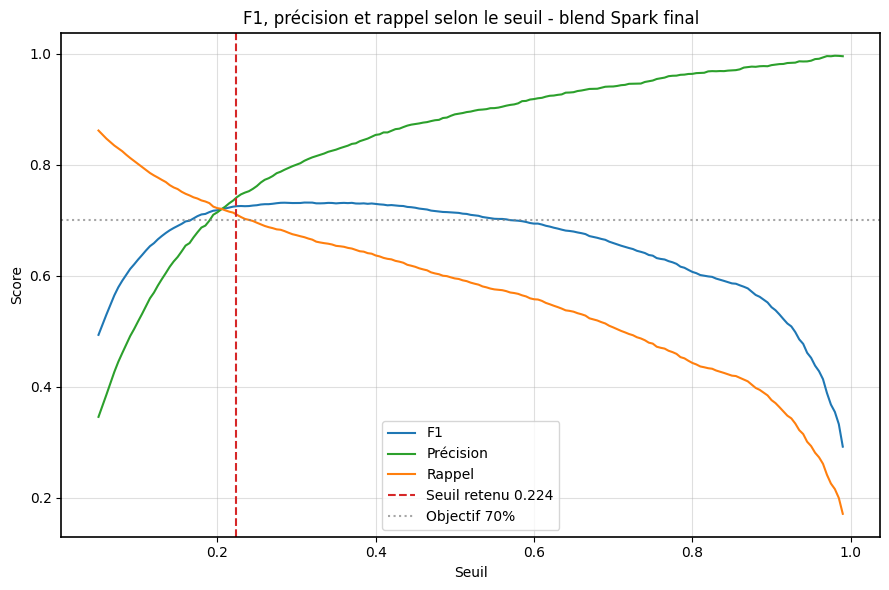

In [41]:
final_blend_sweep = sweep_thresholds(y_score_blend, y_true_blend)
final_blend_sweep.to_csv((METRICS_DIR / "final_blend_threshold_sweep_full_valid.csv").as_posix(), index=False)

plt.figure(figsize=(9, 6))
plt.plot(final_blend_sweep["threshold"], final_blend_sweep["F1"], label="F1", color="#1f77b4")
plt.plot(final_blend_sweep["threshold"], final_blend_sweep["Precision"], label="Précision", color="#2ca02c")
plt.plot(final_blend_sweep["threshold"], final_blend_sweep["Recall"], label="Rappel", color="#ff7f0e")
plt.axvline(final_blend_threshold, color="#d62728", linestyle="--", label=f"Seuil retenu {final_blend_threshold:.3f}")
plt.axhline(0.70, color="grey", linestyle=":", alpha=0.7, label="Objectif 70%")
plt.title("F1, précision et rappel selon le seuil - blend Spark final")
plt.xlabel("Seuil")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid(True, alpha=0.4)

for spine in plt.gca().spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig((PLOTS_DIR / "threshold_final_blend.png").as_posix(), bbox_inches="tight")
plt.show()


### Lecture des courbes finales du blend

Les courbes confirment que le seuil `0.224` est dans une zone de compromis acceptable.

- En dessous du seuil, le rappel augmente, mais la précision se dégrade vite.
- Au-dessus du seuil, la précision progresse peu alors que le rappel recule.
- Le point retenu garde `Precision = 0.7415` et `Recall = 0.7106` sur `full_valid`.
- Conclusion : le seuil est cohérent avec l'objectif opérationnel du notebook.

### Sauvegarde finale des artefacts

On termine par la sauvegarde MLflow et les artefacts du stage : métriques CSV, JSON de sélection, modèles, graphiques et manifeste du prédicteur final.

Important : `final_model` dans MLflow correspond au GBT Spark de base. Le manifeste final documente les chemins nécessaires pour reconstruire le blend réellement retenu.

In [42]:
model_path = load_json(METADATA_DIR / "final_model_path.json")["model_path"]

blend_config_path = METADATA_DIR / "blend_probability_candidate_selection.json"
blend_config = load_json(blend_config_path)
blend_strategy = blend_config.get("strategy", "unknown")
calibrators_path = METADATA_DIR / "blend_isotonic_calibrators.joblib"

final_predictor_manifest = {
    "predictor_type": "spark_gbt_probability_blend",
    "blend_strategy": blend_strategy,
    "note": (
        "MLflow final_model contient le GBT Spark de base. "
        "Le prédicteur final doit aussi charger la configuration du blend "
        "et, si nécessaire, ses calibrateurs."
    ),
    "base_model_path": model_path,
    "variant_model_paths": {
        "gbt_classWeight_x1.15": (MODELS_STAGE_DIR / "gbt_classWeight_x1.15").as_posix(),
        "gbt_classWeight_x1.30": (MODELS_STAGE_DIR / "gbt_classWeight_x1.30").as_posix(),
    },
    "blend_config_path": blend_config_path.as_posix(),
    "final_features_path": (METADATA_DIR / "final_features_optimized.json").as_posix(),
    "optimized_feature_metadata_path": (METADATA_DIR / "optimized_feature_metadata.json").as_posix(),
    "stage_artifacts_path": STAGE_ARTIFACTS_DIR.as_posix(),
}

if blend_strategy == "cal":
    if not calibrators_path.exists():
        raise FileNotFoundError(f"Calibrateurs du blend introuvables : {calibrators_path}")
    final_predictor_manifest["blend_calibrators_path"] = calibrators_path.as_posix()

save_json(METADATA_DIR / "final_predictor_manifest.json", final_predictor_manifest)

safe_mlflow_log_model(best_model, artifact_path="final_model", context="final spark base model")
safe_mlflow_log_artifacts(STAGE_ARTIFACTS_DIR.as_posix(), artifact_path=STAGE_NAME, context="stage artifacts")
mlflow.end_run()

print(f"Artifacts sauvegardés dans {STAGE_ARTIFACTS_DIR}")
print("Fichiers clés :")
print(f"- Manifeste prédicteur final : {METADATA_DIR / 'final_predictor_manifest.json'}")
print(f"- Blend final : {METADATA_DIR / 'blend_probability_candidate_selection.json'}")
print(f"- Métriques blend : {METRICS_DIR / 'final_blend_curve_metrics.csv'}")
print(f"- Courbe ROC blend : {PLOTS_DIR / 'roc_final_blend.png'}")
print(f"- Courbe PR blend : {PLOTS_DIR / 'pr_final_blend.png'}")
print(f"- Courbe seuil blend : {PLOTS_DIR / 'threshold_final_blend.png'}")
if (METADATA_DIR / "meta_reranker_candidate_selection.json").exists():
    print(f"- Annexe méta-reranker : {METADATA_DIR / 'meta_reranker_candidate_selection.json'}")

2026/07/14 17:13:32 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\EL-FAH~1\AppData\Local\Temp\tmp7q_d9khh\model, flavor: spark). Fall back to return ['pyspark==3.5.5']. Set logging level to DEBUG to see the full traceback. 


Artifacts sauvegardés dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model
Fichiers clés :
- Manifeste prédicteur final : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\metadata\final_predictor_manifest.json
- Blend final : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\metadata\blend_probability_candidate_selection.json
- Métriques blend : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\metrics\final_blend_curve_metrics.csv
- Courbe ROC blend : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\plots\roc_final_blend.png
- Courbe PR blend : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\plots\pr_final_blend.png
- Courbe seuil blend : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\plots\threshold_final_b